In [1]:
import os

#cell that have all of the imports
# Data
import numpy as np
import pandas as pd

# visualization
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# pytorch
import torch
import torch.nn.functional as F
from torch import nn, tensor
from torch.utils.data import DataLoader, Dataset

# torchvision
from torchvision import transforms, models
from torchvision.transforms import functional as TF

# fastai
from fastai.vision.all import *
from fastai.tabular.all import *
from fastai.data.transforms import RandomSplitter
from fastai.callback.hook import *

# sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Data

## read the data

In [2]:
#get our path
os.getcwd()

'/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/personal/spaceship_titanic'

In [3]:
data_path = Path("./data")

In [4]:
# unzip the files
import zipfile
with zipfile.ZipFile(data_path/"spaceship-titanic.zip", 'r') as z:
    z.extractall("./Data")

In [5]:
trn_data = data_path/"train.csv"
tst_data = data_path/"test.csv"

In [6]:
df = pd.read_csv(trn_data)
df

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False


## Explore data
- check for the missing values
- See the nan and how many
- describe(the str and numbers)
- historgrams and plots for the numbers

In [7]:
df.describe(include=(np.number)).round(3)

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000,8512.000,8510.000,8485.000,8510.000,8505.000
mean,28.828,224.688,458.077,173.729,311.139,304.855
std,14.489,666.718,1611.489,604.696,1136.706,1145.717
min,0.000,0.000,0.000,0.000,0.000,0.000
25%,19.000,0.000,0.000,0.000,0.000,0.000
50%,27.000,0.000,0.000,0.000,0.000,0.000
75%,38.000,47.000,76.000,27.000,59.000,46.000
max,79.000,14327.000,29813.000,23492.000,22408.000,24133.000


In [8]:
df.describe(include=(object))

/tmp/ipykernel_20602/314228888.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=(object))


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,VIP,Name
count,8693,8492,8476,8494,8511,8490,8493
unique,8693,3,2,6560,3,2,8473
top,0001_01,Earth,False,G/734/S,TRAPPIST-1e,False,Elaney Webstephrey
freq,1,4602,5439,8,5915,8291,2


In [9]:
df.isna().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

In [10]:
# getting the percentage of the nan in the Data
df.isna().mean() * 100

PassengerId     0.000000
HomePlanet      2.312205
CryoSleep       2.496261
Cabin           2.289198
Destination     2.093639
Age             2.059128
VIP             2.335212
RoomService     2.082135
FoodCourt       2.105142
ShoppingMall    2.392730
Spa             2.105142
VRDeck          2.162660
Name            2.300702
Transported     0.000000
dtype: float64

In [11]:
df.nunique().sort_values()

CryoSleep          2
VIP                2
Transported        2
Destination        3
HomePlanet         3
Age               80
ShoppingMall    1115
RoomService     1273
VRDeck          1306
Spa             1327
FoodCourt       1507
Cabin           6560
Name            8473
PassengerId     8693
dtype: int64

In [12]:
df.Destination.unique() , df.HomePlanet.unique()

(<ArrowStringArray>
 ['TRAPPIST-1e', 'PSO J318.5-22', '55 Cancri e', nan]
 Length: 4, dtype: str,
 <ArrowStringArray>
 ['Europa', 'Earth', 'Mars', nan]
 Length: 4, dtype: str)

In [13]:
 # look on how many are asleep and %
df.CryoSleep.value_counts() ,(df.CryoSleep.value_counts(normalize=True)*100).round(3)

(CryoSleep
 False    5439
 True     3037
 Name: count, dtype: int64,
 CryoSleep
 False    64.169
 True     35.831
 Name: proportion, dtype: float64)

In [14]:
 # look on how many are VIP and %
 df.VIP.value_counts(), (df.VIP.value_counts(normalize=True)*100).round(3)

(VIP
 False    8291
 True      199
 Name: count, dtype: int64,
 VIP
 False    97.656
 True      2.344
 Name: proportion, dtype: float64)

In [15]:
# see the coleration between the Data columns and the target
corr =  df.corr(numeric_only=True)['Transported'].sort_values(ascending=False) # make it sorted so that the most close is the most correlation
corr = corr.drop('Transported') # remove the correlation with itself
corr

FoodCourt       0.046566
ShoppingMall    0.010141
Age            -0.075026
VRDeck         -0.207075
Spa            -0.221131
RoomService    -0.244611
Name: Transported, dtype: float64

Text(0.5, 1.0, 'Correlation Coefficient')

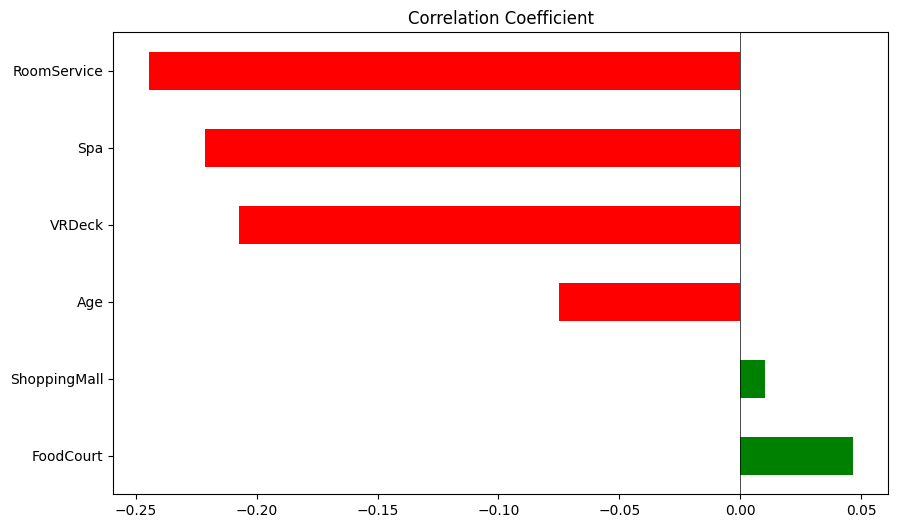

In [16]:
# make a plot
plt.figure(figsize=(10,6))
corr.plot(kind='barh', # this can be a lot of things
          color =['green' if x > 0 else 'red' for x in corr])
plt.axvline(x=0, color='black', linewidth=0.5) # this added extra to make it look better
plt.title('Correlation Coefficient')

Here we can see that the strongest correlations are for Rob Service and Spa and VR deck because they are in highly inversely proportional.

In [17]:
# this splits the Data into --> trans and not trans and then takes the mean for each group
df.groupby('Transported').mean(numeric_only=True).round(3)

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
Transported,,,,,,
False,29.923,389.266,382.616,167.566,564.383,543.630
True,27.749,63.098,532.692,179.830,61.676,69.148


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 1.2+ MB


In [19]:
df[df['CryoSleep'] == True]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
7,0006_02,Earth,True,G/0/S,TRAPPIST-1e,28.0,False,0.0,0.0,0.0,0.0,NaN,Candra Jacostaffey,True
9,0008_01,Europa,True,B/1/P,55 Cancri e,14.0,False,0.0,0.0,0.0,0.0,0.0,Erraiam Flatic,True
10,0008_02,Europa,True,B/1/P,TRAPPIST-1e,34.0,False,0.0,0.0,NaN,0.0,0.0,Altardr Flatic,True
18,0016_01,Mars,True,F/5/P,TRAPPIST-1e,45.0,False,0.0,0.0,0.0,0.0,0.0,Alus Upead,True
21,0020_01,Earth,True,E/0/S,TRAPPIST-1e,1.0,False,0.0,0.0,0.0,0.0,0.0,Almary Brantuarez,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8679,9267_02,Europa,True,E/607/S,TRAPPIST-1e,20.0,False,0.0,0.0,0.0,0.0,0.0,Sabi Opshaft,True
8680,9268_01,Earth,True,G/1505/P,TRAPPIST-1e,31.0,False,0.0,0.0,0.0,0.0,0.0,Agnesa Baldson,True
8681,9270_01,Earth,True,G/1497/S,55 Cancri e,33.0,False,0.0,0.0,0.0,0.0,0.0,Lan Mckinsond,True
8684,9274_01,NaN,True,G/1508/P,TRAPPIST-1e,23.0,False,0.0,0.0,0.0,0.0,0.0,Chelsa Bullisey,True


In [20]:
# we can see that all of the people that are asleep didn't spend anything --> so that can halp us for the fill nan to be more accurate
df[df['CryoSleep'] == True].nunique()

PassengerId     3037
HomePlanet         3
CryoSleep          1
Cabin           2437
Destination        3
Age               78
VIP                2
RoomService        1
FoodCourt          1
ShoppingMall       1
Spa                1
VRDeck             1
Name            2973
Transported        2
dtype: int64

## Clean the data

In [21]:
# lets now make a total spending column
spend_cols = ['RoomService','FoodCourt','ShoppingMall','Spa','VRDeck']
df['Money_spent'] = df[spend_cols].sum(axis=1) # for any nan value the sum() is going to skip it by default
df

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Money_spent
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,0.0
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,736.0
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,10383.0
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,5176.0
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,1091.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False,8536.0
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False,0.0
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True,1873.0
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False,4637.0


In [22]:
# zero_money df is a view not a copy of df
zero_money = df[df['Money_spent'] == 0]
zero_money

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Money_spent
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,0.0
7,0006_02,Earth,True,G/0/S,TRAPPIST-1e,28.0,False,0.0,0.0,0.0,0.0,NaN,Candra Jacostaffey,True,0.0
9,0008_01,Europa,True,B/1/P,55 Cancri e,14.0,False,0.0,0.0,0.0,0.0,0.0,Erraiam Flatic,True,0.0
10,0008_02,Europa,True,B/1/P,TRAPPIST-1e,34.0,False,0.0,0.0,NaN,0.0,0.0,Altardr Flatic,True,0.0
18,0016_01,Mars,True,F/5/P,TRAPPIST-1e,45.0,False,0.0,0.0,0.0,0.0,0.0,Alus Upead,True,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8680,9268_01,Earth,True,G/1505/P,TRAPPIST-1e,31.0,False,0.0,0.0,0.0,0.0,0.0,Agnesa Baldson,True,0.0
8681,9270_01,Earth,True,G/1497/S,55 Cancri e,33.0,False,0.0,0.0,0.0,0.0,0.0,Lan Mckinsond,True,0.0
8684,9274_01,NaN,True,G/1508/P,TRAPPIST-1e,23.0,False,0.0,0.0,0.0,0.0,0.0,Chelsa Bullisey,True,0.0
8685,9275_01,Europa,False,A/97/P,TRAPPIST-1e,0.0,False,0.0,0.0,0.0,0.0,0.0,Polaton Conable,True,0.0


In [23]:
# lets See how many of the zero spenders are Cryosleep (We know for a fact that all crew sleep are zero spenders)
(zero_money['CryoSleep'].value_counts(normalize=True)*100).round(3)

CryoSleep
True     85.429
False    14.571
Name: proportion, dtype: float64

In [24]:
CryoSleep_musk = df['CryoSleep'] == True # this is a boolean musk
CryoSleep_musk

0       False
1       False
2       False
3       False
4       False
        ...  
8688    False
8689     True
8690    False
8691    False
8692    False
Name: CryoSleep, Length: 8693, dtype: bool

In [25]:
# now lets fill nan (Where if someone is asleep he spends zero)
for col in spend_cols:
    df.loc[CryoSleep_musk,col]  =  df.loc[CryoSleep_musk,col].fillna(0) # we have to use the loc for making this musk thing

# verify
df.loc[df['CryoSleep'] == True, spend_cols].isna().sum()

RoomService     0
FoodCourt       0
ShoppingMall    0
Spa             0
VRDeck          0
dtype: int64

We made this step because we are 100% sure of that this is the correct.

In [26]:
# this is how much roles we are going to lose if we use drop nan
(1-(len(df.dropna())/len(df)))*100

20.545266306223397

- That is too much amount of data to drop for rows that have nan values . It would be alright if it was just five percent or something and also it depends on a lot of factors.
- So now we are going to feel the then with mode for categorical variables and the mean for numerical values---- (As a baseline and we could use a cyclic learn library that is a model that feels missing values by using pattern recognition. But that could be used later.) ----
- (I have mentioned all that 85% of the people that didn't spend the money were asleep, but we can't use this because it's too risky [What I mean by using is to make everybody that has zero spendings asleep])

In [27]:
print(df['HomePlanet'].mode())
print("---")
df['HomePlanet'].mode()[0]

0    Earth
Name: HomePlanet, dtype: str
---


'Earth'

- MEAN   = sum of all values / count -------- [RETURN LIST] -> [0] NEEDED
- MEDIAN = middle value when sorted ( better at things like money becasue few people spend alot) ------ [RETURN NUMBER DIRECTLY]

## Make dummy variables[added columns], make log if needed , etc...

In [28]:
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Money_spent
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,0.0
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,736.0
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,10383.0
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,5176.0
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,1091.0


In [29]:
df.describe().round(2)

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Money_spent
count,8514.00,8580.00,8580.00,8581.00,8575.00,8567.00,8693.00
mean,28.83,222.91,454.34,171.79,308.78,302.65,1440.87
std,14.49,664.37,1605.43,601.58,1132.71,1141.86,2803.05
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,19.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,27.00,0.00,0.00,0.00,0.00,0.00,716.00
75%,38.00,44.00,70.00,24.00,58.00,44.00,1441.00
max,79.00,14327.00,29813.00,23492.00,22408.00,24133.00,35987.00


In [30]:
df.describe(include=(object))

/tmp/ipykernel_20602/314228888.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=(object))


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,VIP,Name
count,8693,8492,8476,8494,8511,8490,8493
unique,8693,3,2,6560,3,2,8473
top,0001_01,Earth,False,G/734/S,TRAPPIST-1e,False,Elaney Webstephrey
freq,1,4602,5439,8,5915,8291,2


In [31]:
df.isna().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     113
FoodCourt       113
ShoppingMall    112
Spa             118
VRDeck          126
Name            200
Transported       0
Money_spent       0
dtype: int64

In [32]:
# make the mode for the homeplanet and destinaiton before making the dummies because if we didt it is going ot make all of the nan(s) -->0,0,0....
cat_cols = ['HomePlanet', 'Destination']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [33]:
# lets make dummy variables
df = pd.get_dummies(df, columns=['HomePlanet','Destination'],dtype=int)
df.columns

Index(['PassengerId', 'CryoSleep', 'Cabin', 'Age', 'VIP', 'RoomService',
       'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name', 'Transported',
       'Money_spent', 'HomePlanet_Earth', 'HomePlanet_Europa',
       'HomePlanet_Mars', 'Destination_55 Cancri e',
       'Destination_PSO J318.5-22', 'Destination_TRAPPIST-1e'],
      dtype='str')

In [34]:
# make the True - False columns to numbers
bool_cols = df.select_dtypes(include='bool').columns
bool_cols

Index(['Transported'], dtype='str')

In [35]:
df[bool_cols] = df[bool_cols].astype(int)
df.head()

,PassengerId,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Money_spent,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e
0,0001_01,False,B/0/P,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,0,0.0,0,1,0,0,0,1
1,0002_01,False,F/0/S,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,1,736.0,1,0,0,0,0,1
2,0003_01,False,A/0/S,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,0,10383.0,0,1,0,0,0,1
3,0003_02,False,A/0/S,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,0,5176.0,0,1,0,0,0,1
4,0004_01,False,F/1/S,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,1,1091.0,1,0,0,0,0,1


In [36]:
df['CryoSleep'].value_counts()

CryoSleep
False    5439
True     3037
Name: count, dtype: int64

In [37]:
# make the VIP and the sleep as 0,1 bec they are not bool type they are object type

In [38]:
df['CryoSleep'] = df['CryoSleep'].astype(str).map({'True': 1, 'False': 0})
df['VIP'] = df['VIP'].astype(str).map({'True': 1, 'False': 0})

In [39]:
df.loc[0]

PassengerId                          0001_01
CryoSleep                                0.0
Cabin                                  B/0/P
Age                                     39.0
VIP                                      0.0
RoomService                              0.0
FoodCourt                                0.0
ShoppingMall                             0.0
Spa                                      0.0
VRDeck                                   0.0
Name                         Maham Ofracculy
Transported                                0
Money_spent                              0.0
HomePlanet_Earth                           0
HomePlanet_Europa                          1
HomePlanet_Mars                            0
Destination_55 Cancri e                    0
Destination_PSO J318.5-22                  0
Destination_TRAPPIST-1e                    1
Name: 0, dtype: object

In [40]:
df_raw = df.copy()

# Making the models and the training funciton

Manual:
- a dataframe that we are going to enter and we are going to enter the name of the data frame manually
- we are going to have a function that  makes use all of the trn and val data
- we are going to make the training and get the score
- then we are going to make a dicitonary for this model and then we are going to make the name of the thing is this  df_name + model_name
- and then we are going to put it in the results

In [41]:
# imports
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

import copy

In [42]:
# first we are going to make the results variable that will store all of the results
results = []



Decision Tree / Random Forest

        max_depth — how many levels of splits
        depth=1          depth=3
        Age>30?          Age>30?
        /     \          /      \
      DEAD   ALIVE   Fare>50?  VIP=1?
                     /    \    /    \
                    DEAD  ALIVE ...   ...

      too high → memorizes training data (overfit)
      too low  → too simple (underfit)
      min_samples_leaf — min people needed in a leaf
      =1 : can end on ONE person → memorizes → overfit
      =4 : needs 4 people to agree → more general → better

n_estimators — how many trees (random forest only)

      max_features='sqrt' — columns each tree sees
      15 columns → each tree sees sqrt(15)≈4 random columns


Logistic Regression

C — inverse of weight penalty (same idea as weight decay)

      small C = punish big weights hard = simple model
      large C = allow big weights      = complex model

      C=0.01 → w=[0.3,-0.1,0.5]   ← very controlled
      C=1.0  → w=[2.1,-1.3,3.2]   ← medium (default)
      C=100  → w=[45, -23, 67]    ← close to no penalty

Gradient Boosting (XGBoost)

      tree1 trains → has errors
      tree2 trains on errors of tree1
      tree3 trains on errors of tree1+tree2
      each tree fixes what previous ones got wrong

      learning_rate=0.05 → add 5% correction each tree
      small lr = slower but more stable
      recommended: learning_rate=0.05, n_estimators=200

In [43]:
models = {
    'Logistic Regression': LogisticRegression(
        C=0.1,           # dataset is clean enough, slight penalty is fine
        max_iter=1000
    ),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=6,          # 8693 rows → can go a bit deeper than 5
        min_samples_leaf=10,  # 8693 rows → 10 is safer than 4
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=300,     # more rows → more trees worth it
        max_depth=8,          # deeper ok with this many rows
        min_samples_leaf=5,   # 5 is safe for this size
        max_features='sqrt'
    ),
    'Neural Network': MLPClassifier(
        hidden_layer_sizes=(100, 50),  # two layers is enough
        max_iter=500,                  # 8693 rows → 500 is fine
        learning_rate_init=0.001
    ),
    'XGBoost': XGBClassifier(
        n_estimators=300,      # chain of 300 trees
        max_depth=5,           # keep shallow for boosting
        learning_rate=0.05,    # slow and stable
        eval_metric='logloss'
    )
}

In [44]:
# function that makes the Data splits
def make_trn_val_split (df):
    x = df.drop('Transported' ,axis=1)
    y = df['Transported']
    x_train , x_val , y_train , y_val = train_test_split(x , y , test_size = 0.2 , random_state = 42)
    return x_train , x_val , y_train , y_val

In [45]:
# train and eval function
def train_eval_fn (model,x_train,x_val,y_train,y_val):
    model.fit(x_train,y_train)
    score = accuracy_score(y_val,model.predict(x_val))
    return score

In [46]:
def full_fn (df_name,df,models=models):
    x_train , x_val , y_train , y_val = make_trn_val_split(df)
    for model_name,model in models.items():
        fresh_model = copy.deepcopy(model)  # fresh model every time
        score = train_eval_fn(fresh_model , x_train , x_val , y_train , y_val)
        score = round(score,5)
        print(f'[INFO]  Data : {df_name}  | Model : {model_name}   | Score : {score} ')
        results.append({
            'Data' : df_name,
            'Model' : model_name,
            'Score' : score
        })

# Making different df and feature engineering

## Try the raw df

### Ceaning

In [47]:
df.head()

,PassengerId,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Money_spent,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e
0,0001_01,0.0,B/0/P,39.0,0.0,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,0,0.0,0,1,0,0,0,1
1,0002_01,0.0,F/0/S,24.0,0.0,109.0,9.0,25.0,549.0,44.0,Juanna Vines,1,736.0,1,0,0,0,0,1
2,0003_01,0.0,A/0/S,58.0,1.0,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,0,10383.0,0,1,0,0,0,1
3,0003_02,0.0,A/0/S,33.0,0.0,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,0,5176.0,0,1,0,0,0,1
4,0004_01,0.0,F/1/S,16.0,0.0,303.0,70.0,151.0,565.0,2.0,Willy Santantines,1,1091.0,1,0,0,0,0,1


In [48]:
# remove the string from the df
df = df.drop(['PassengerId','Cabin','Name'] , axis=1)

In [49]:
# see the nan
df.isna().sum()

CryoSleep                    217
Age                          179
VIP                          203
RoomService                  113
FoodCourt                    113
ShoppingMall                 112
Spa                          118
VRDeck                       126
Transported                    0
Money_spent                    0
HomePlanet_Earth               0
HomePlanet_Europa              0
HomePlanet_Mars                0
Destination_55 Cancri e        0
Destination_PSO J318.5-22      0
Destination_TRAPPIST-1e        0
dtype: int64

In [50]:
spend_cols

['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

In [51]:
# let's clean the nan
num_cols = ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# remake the money spent col
df['Money_spent'] =df[spend_cols].sum(axis=1)

# make for the sleep and VIP the mode()
mode_cols = ['CryoSleep','VIP']
for col in mode_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

<Axes: >

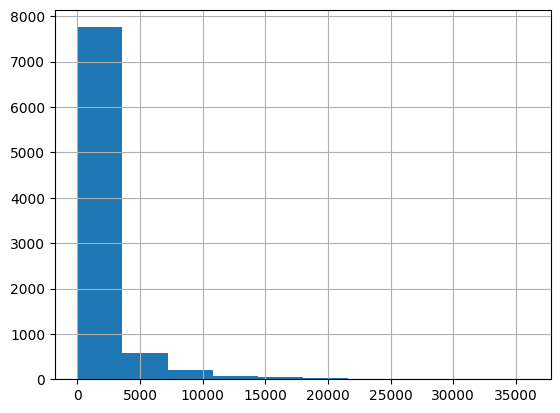

In [52]:
df['Money_spent'].hist()

In [53]:
df['Age'].max()

np.float64(79.0)

In [54]:
# normalizing the Age
df['Age'] = df['Age'] / df['Age'].max()
df.head()

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Money_spent,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e
0,0.0,0.493671,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0,1,0,0,0,1
1,0.0,0.303797,0.0,109.0,9.0,25.0,549.0,44.0,1,736.0,1,0,0,0,0,1
2,0.0,0.734177,1.0,43.0,3576.0,0.0,6715.0,49.0,0,10383.0,0,1,0,0,0,1
3,0.0,0.417722,0.0,0.0,1283.0,371.0,3329.0,193.0,0,5176.0,0,1,0,0,0,1
4,0.0,0.202532,0.0,303.0,70.0,151.0,565.0,2.0,1,1091.0,1,0,0,0,0,1


In [55]:
full_money_cols = spend_cols+['Money_spent']
full_money_cols

['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Money_spent']

In [56]:
# now for the money we are going to make it through log First and then divided by the biggest number.
for col in full_money_cols:
    df[col] = np.log(df[col] + 1)

<Axes: >

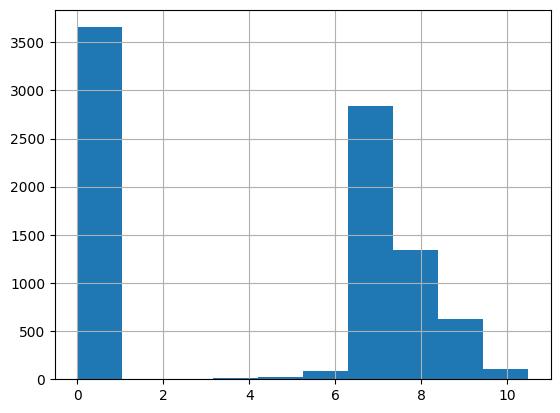

In [57]:
df['Money_spent'].hist()

In [58]:
for col in full_money_cols:
    df[col] = df[col] / df[col].max()

<Axes: >

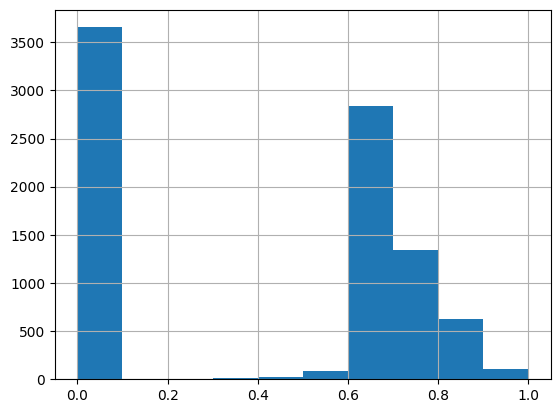

In [59]:
df['Money_spent'].hist()

In [60]:
df.head(2)

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Money_spent,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e
0,0.0,0.493671,0.0,0.00000,0.000000,0.000000,0.000000,0.000000,0,0.000000,0,1,0,0,0,1
1,0.0,0.303797,0.0,0.49117,0.223493,0.323723,0.629907,0.377219,1,0.629361,1,0,0,0,0,1


In [61]:
df.describe().round(2)

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Money_spent,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e
count,8693.00,8693.00,8693.00,8693.00,8693.00,8693.00,8693.00,8693.00,8693.0,8693.00,8693.00,8693.00,8693.0,8693.00,8693.00,8693.00
mean,0.35,0.36,0.02,0.18,0.19,0.16,0.18,0.17,0.5,0.41,0.55,0.25,0.2,0.21,0.09,0.70
std,0.48,0.18,0.15,0.28,0.28,0.26,0.28,0.27,0.5,0.35,0.50,0.43,0.4,0.41,0.29,0.46
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.0,0.00,0.00,0.00
25%,0.00,0.25,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.0,0.00,0.00,0.00
50%,0.00,0.34,0.00,0.00,0.00,0.00,0.00,0.00,1.0,0.63,1.00,0.00,0.0,0.00,0.00,1.00
75%,1.00,0.47,0.00,0.39,0.40,0.31,0.40,0.37,1.0,0.69,1.00,0.00,0.0,0.00,0.00,1.00
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.00,1.00,1.00,1.0,1.00,1.00,1.00


### Train

In [62]:
full_fn("DF_Raw",df=df)

[INFO]  Data : DF_Raw  | Model : Logistic Regression   | Score : 0.76596 
[INFO]  Data : DF_Raw  | Model : Decision Tree   | Score : 0.77573 
[INFO]  Data : DF_Raw  | Model : Random Forest   | Score : 0.78493 
[INFO]  Data : DF_Raw  | Model : Neural Network   | Score : 0.78551 
[INFO]  Data : DF_Raw  | Model : XGBoost   | Score : 0.78953 


## Second

### Cleaning

In [63]:
df = df_raw.copy()
df

,PassengerId,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Money_spent,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e
0,0001_01,0.0,B/0/P,39.0,0.0,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,0,0.0,0,1,0,0,0,1
1,0002_01,0.0,F/0/S,24.0,0.0,109.0,9.0,25.0,549.0,44.0,Juanna Vines,1,736.0,1,0,0,0,0,1
2,0003_01,0.0,A/0/S,58.0,1.0,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,0,10383.0,0,1,0,0,0,1
3,0003_02,0.0,A/0/S,33.0,0.0,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,0,5176.0,0,1,0,0,0,1
4,0004_01,0.0,F/1/S,16.0,0.0,303.0,70.0,151.0,565.0,2.0,Willy Santantines,1,1091.0,1,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,0.0,A/98/P,41.0,1.0,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,0,8536.0,0,1,0,1,0,0
8689,9278_01,1.0,G/1499/S,18.0,0.0,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,0,0.0,1,0,0,0,1,0
8690,9279_01,0.0,G/1500/S,26.0,0.0,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,1,1873.0,1,0,0,0,0,1
8691,9280_01,0.0,E/608/S,32.0,0.0,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,0,4637.0,0,1,0,1,0,0


In [64]:
df = df.dropna()
df

,PassengerId,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Money_spent,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e
0,0001_01,0.0,B/0/P,39.0,0.0,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,0,0.0,0,1,0,0,0,1
1,0002_01,0.0,F/0/S,24.0,0.0,109.0,9.0,25.0,549.0,44.0,Juanna Vines,1,736.0,1,0,0,0,0,1
2,0003_01,0.0,A/0/S,58.0,1.0,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,0,10383.0,0,1,0,0,0,1
3,0003_02,0.0,A/0/S,33.0,0.0,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,0,5176.0,0,1,0,0,0,1
4,0004_01,0.0,F/1/S,16.0,0.0,303.0,70.0,151.0,565.0,2.0,Willy Santantines,1,1091.0,1,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,0.0,A/98/P,41.0,1.0,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,0,8536.0,0,1,0,1,0,0
8689,9278_01,1.0,G/1499/S,18.0,0.0,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,0,0.0,1,0,0,0,1,0
8690,9279_01,0.0,G/1500/S,26.0,0.0,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,1,1873.0,1,0,0,0,0,1
8691,9280_01,0.0,E/608/S,32.0,0.0,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,0,4637.0,0,1,0,1,0,0


In [65]:
df.isna().sum()

PassengerId                  0
CryoSleep                    0
Cabin                        0
Age                          0
VIP                          0
RoomService                  0
FoodCourt                    0
ShoppingMall                 0
Spa                          0
VRDeck                       0
Name                         0
Transported                  0
Money_spent                  0
HomePlanet_Earth             0
HomePlanet_Europa            0
HomePlanet_Mars              0
Destination_55 Cancri e      0
Destination_PSO J318.5-22    0
Destination_TRAPPIST-1e      0
dtype: int64

In [66]:
# remove the string from the df
df = df.drop(['PassengerId', 'Cabin', 'Name'], axis=1)

In [67]:
# remake the money spent col
df['Money_spent'] = df[spend_cols].sum(axis=1)

In [68]:
# normalizing the Age
df['Age'] = df['Age'] / df['Age'].max()

In [69]:
full_money_cols = spend_cols + ['Money_spent']
full_money_cols

['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Money_spent']

In [70]:
# now for the money we are going to make it through log First and then divided by the biggest number.
for col in full_money_cols:
    df[col] = np.log(df[col] + 1)
    df[col] = df[col] / df[col].max()

<Axes: >

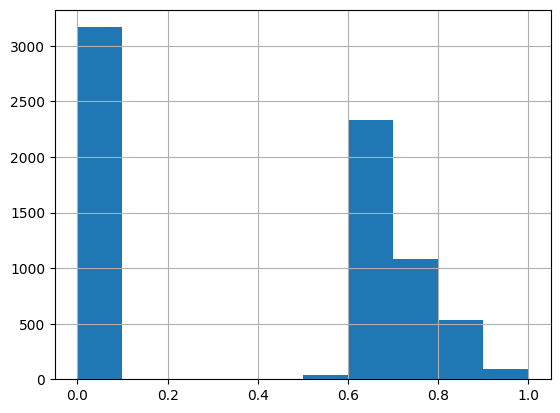

In [71]:
df['Money_spent'].hist()

In [72]:
df.head(2)


,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Money_spent,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e
0,0.0,0.493671,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0,0.000000,0,1,0,0,0,1
1,0.0,0.303797,0.0,0.510788,0.223493,0.346105,0.629907,0.383729,1,0.629361,1,0,0,0,0,1


### Train

In [73]:
full_fn("DF_ALL_NAN_NAMES_DROPPED",df=df)

[INFO]  Data : DF_ALL_NAN_NAMES_DROPPED  | Model : Logistic Regression   | Score : 0.76572 
[INFO]  Data : DF_ALL_NAN_NAMES_DROPPED  | Model : Decision Tree   | Score : 0.77332 
[INFO]  Data : DF_ALL_NAN_NAMES_DROPPED  | Model : Random Forest   | Score : 0.78438 
[INFO]  Data : DF_ALL_NAN_NAMES_DROPPED  | Model : Neural Network   | Score : 0.77402 
[INFO]  Data : DF_ALL_NAN_NAMES_DROPPED  | Model : XGBoost   | Score : 0.77747 


## Third

### Cleaning

In [74]:
df = df_raw.copy()
df

,PassengerId,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Money_spent,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e
0,0001_01,0.0,B/0/P,39.0,0.0,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,0,0.0,0,1,0,0,0,1
1,0002_01,0.0,F/0/S,24.0,0.0,109.0,9.0,25.0,549.0,44.0,Juanna Vines,1,736.0,1,0,0,0,0,1
2,0003_01,0.0,A/0/S,58.0,1.0,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,0,10383.0,0,1,0,0,0,1
3,0003_02,0.0,A/0/S,33.0,0.0,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,0,5176.0,0,1,0,0,0,1
4,0004_01,0.0,F/1/S,16.0,0.0,303.0,70.0,151.0,565.0,2.0,Willy Santantines,1,1091.0,1,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,0.0,A/98/P,41.0,1.0,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,0,8536.0,0,1,0,1,0,0
8689,9278_01,1.0,G/1499/S,18.0,0.0,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,0,0.0,1,0,0,0,1,0
8690,9279_01,0.0,G/1500/S,26.0,0.0,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,1,1873.0,1,0,0,0,0,1
8691,9280_01,0.0,E/608/S,32.0,0.0,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,0,4637.0,0,1,0,1,0,0


In [75]:
# here we are going to split the group and the group number from the passenger ID
df['group'] = df['PassengerId'].str.split('_').str[0].astype(int) # what the str.split return Series of lists → ['0001', '01']
                                                                  # we made the type from str to int
df['group_num'] = df['PassengerId'].str.split('_').str[1].astype(int)

df['group'].unique() , df['group_num'].unique()

(array([   1,    2,    3, ..., 9278, 9279, 9280], shape=(6217,)),
 array([1, 2, 3, 4, 5, 6, 7, 8]))

In [76]:
df.head(4)

,PassengerId,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,...,Transported,Money_spent,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e,group,group_num
0,0001_01,0.0,B/0/P,39.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0.0,0,1,0,0,0,1,1,1
1,0002_01,0.0,F/0/S,24.0,0.0,109.0,9.0,25.0,549.0,44.0,...,1,736.0,1,0,0,0,0,1,2,1
2,0003_01,0.0,A/0/S,58.0,1.0,43.0,3576.0,0.0,6715.0,49.0,...,0,10383.0,0,1,0,0,0,1,3,1
3,0003_02,0.0,A/0/S,33.0,0.0,0.0,1283.0,371.0,3329.0,193.0,...,0,5176.0,0,1,0,0,0,1,3,2


In [77]:
# we are going to drop the group column and the passenger id because we dont need them
df.drop(['group','PassengerId'],axis=1 , inplace=True)
df.columns

Index(['CryoSleep', 'Cabin', 'Age', 'VIP', 'RoomService', 'FoodCourt',
       'ShoppingMall', 'Spa', 'VRDeck', 'Name', 'Transported', 'Money_spent',
       'HomePlanet_Earth', 'HomePlanet_Europa', 'HomePlanet_Mars',
       'Destination_55 Cancri e', 'Destination_PSO J318.5-22',
       'Destination_TRAPPIST-1e', 'group_num'],
      dtype='str')

Alright, let's see if we are going to make  mode and median or drop naa rows

In [78]:
pd.DataFrame(results)

,Data,Model,Score
0,DF_Raw,Logistic Regression,0.76596
1,DF_Raw,Decision Tree,0.77573
2,DF_Raw,Random Forest,0.78493
3,DF_Raw,Neural Network,0.78551
4,DF_Raw,XGBoost,0.78953
5,DF_ALL_NAN_NAMES_DROPPED,Logistic Regression,0.76572
6,DF_ALL_NAN_NAMES_DROPPED,Decision Tree,0.77332
7,DF_ALL_NAN_NAMES_DROPPED,Random Forest,0.78438
8,DF_ALL_NAN_NAMES_DROPPED,Neural Network,0.77402
9,DF_ALL_NAN_NAMES_DROPPED,XGBoost,0.77747


We are going for the median and mode , because better results

In [79]:
# remove the string from the df
df = df.drop(['Cabin', 'Name'], axis=1)

In [80]:
# let's clean the nan
num_cols = ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [81]:
# remake the money spent col
df['Money_spent'] = df[spend_cols].sum(axis=1)

In [82]:
# make for the sleep and VIP the mode()
mode_cols = ['CryoSleep', 'VIP']
for col in mode_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [83]:
# normalizing the Age
df['Age'] = df['Age'] / df['Age'].max()

In [84]:
full_money_cols = spend_cols + ['Money_spent']

In [85]:
# now for the money we are going to make it through log First and then divided by the biggest number.
for col in full_money_cols:
    df[col] = np.log(df[col] + 1)
    df[col] = df[col] / df[col].max()

df.head(2)

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Money_spent,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e,group_num
0,0.0,0.493671,0.0,0.00000,0.000000,0.000000,0.000000,0.000000,0,0.000000,0,1,0,0,0,1,1
1,0.0,0.303797,0.0,0.49117,0.223493,0.323723,0.629907,0.377219,1,0.629361,1,0,0,0,0,1,1


### Train

In [86]:
full_fn("DF_GROUP_NUM_NOT_DUMMY",df=df)

[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY  | Model : Logistic Regression   | Score : 0.76596 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY  | Model : Decision Tree   | Score : 0.77401 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY  | Model : Random Forest   | Score : 0.78263 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY  | Model : Neural Network   | Score : 0.77746 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY  | Model : XGBoost   | Score : 0.78378 


## Forth

### Make group num dummy

In [87]:
df = pd.get_dummies(df,columns=['group_num'],dtype=int)
df.columns

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'Transported', 'Money_spent', 'HomePlanet_Earth',
       'HomePlanet_Europa', 'HomePlanet_Mars', 'Destination_55 Cancri e',
       'Destination_PSO J318.5-22', 'Destination_TRAPPIST-1e', 'group_num_1',
       'group_num_2', 'group_num_3', 'group_num_4', 'group_num_5',
       'group_num_6', 'group_num_7', 'group_num_8'],
      dtype='str')

In [88]:
df.head(2)

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Money_spent,...,Destination_PSO J318.5-22,Destination_TRAPPIST-1e,group_num_1,group_num_2,group_num_3,group_num_4,group_num_5,group_num_6,group_num_7,group_num_8
0,0.0,0.493671,0.0,0.00000,0.000000,0.000000,0.000000,0.000000,0,0.000000,...,0,1,1,0,0,0,0,0,0,0
1,0.0,0.303797,0.0,0.49117,0.223493,0.323723,0.629907,0.377219,1,0.629361,...,0,1,1,0,0,0,0,0,0,0


### Train

In [89]:
full_fn("DF_GROUP_NUM_DUMMY",df)

[INFO]  Data : DF_GROUP_NUM_DUMMY  | Model : Logistic Regression   | Score : 0.76596 
[INFO]  Data : DF_GROUP_NUM_DUMMY  | Model : Decision Tree   | Score : 0.77286 
[INFO]  Data : DF_GROUP_NUM_DUMMY  | Model : Random Forest   | Score : 0.78091 
[INFO]  Data : DF_GROUP_NUM_DUMMY  | Model : Neural Network   | Score : 0.78091 
[INFO]  Data : DF_GROUP_NUM_DUMMY  | Model : XGBoost   | Score : 0.79068 


## Take a look at what we are going to still take

### Make a plot


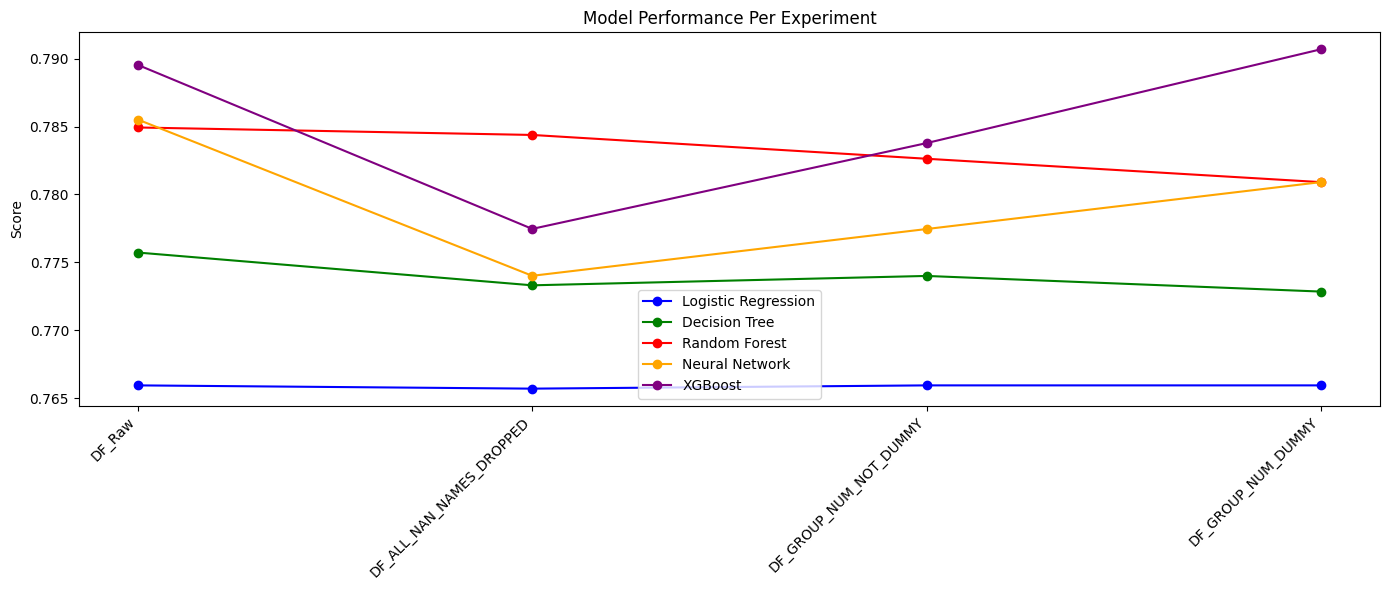

In [90]:
import matplotlib.pyplot as plt
import pandas as pd

# convert to dataframe:
results_df = pd.DataFrame(results)


# assuming your results are already in a dataframe called results_df
# with columns: Data, Model, Scorez

plt.figure(figsize=(14, 6))

models = results_df['Model'].unique()   # get all model names
colors = ['blue', 'green', 'red', 'orange', 'purple']

for model, color in zip(models, colors):
    # filter rows for this model only
    mask = results_df['Model'] == model
    subset = results_df[mask]

    plt.plot(subset['Data'], subset['Score'],
             marker='o',
             label=model,
             color=color)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Score')
plt.title('Model Performance Per Experiment')
plt.legend()
plt.tight_layout()
plt.show()

We can see here that we are going to keep the group number that is not dummy .

## Fifth

### Clean

In [91]:
df = df_raw.copy()

In [92]:
df.columns

Index(['PassengerId', 'CryoSleep', 'Cabin', 'Age', 'VIP', 'RoomService',
       'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name', 'Transported',
       'Money_spent', 'HomePlanet_Earth', 'HomePlanet_Europa',
       'HomePlanet_Mars', 'Destination_55 Cancri e',
       'Destination_PSO J318.5-22', 'Destination_TRAPPIST-1e'],
      dtype='str')

In [93]:
# get the group number
df['group_num'] = df['PassengerId'].str.split('_').str[1].astype(int)

In [94]:
# remove the string from the df
df = df.drop(['PassengerId', 'Name'], axis=1)

In [95]:
# let's clean the nan
num_cols = ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [96]:
# remake the money spent col
df['Money_spent'] = df[spend_cols].sum(axis=1)

In [97]:
# make for the sleep and VIP the mode()
mode_cols = ['CryoSleep', 'VIP','Cabin']
for col in mode_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [98]:
# normalizing the Age
df['Age'] = df['Age'] / df['Age'].max()
full_money_cols = spend_cols + ['Money_spent']

In [99]:
# now for the money we are going to make it through log First and then divided by the biggest number.
for col in full_money_cols:
    df[col] = np.log(df[col] + 1)
    df[col] = df[col] / df[col].max()

df.head(2)

,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Money_spent,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e,group_num
0,0.0,B/0/P,0.493671,0.0,0.00000,0.000000,0.000000,0.000000,0.000000,0,0.000000,0,1,0,0,0,1,1
1,0.0,F/0/S,0.303797,0.0,0.49117,0.223493,0.323723,0.629907,0.377219,1,0.629361,1,0,0,0,0,1,1


Now We are going to split cabin.

In [100]:
cabin_strs = df['Cabin'].str.split('/')
cabin_strs

0          [B, 0, P]
1          [F, 0, S]
2          [A, 0, S]
3          [A, 0, S]
4          [F, 1, S]
            ...     
8688      [A, 98, P]
8689    [G, 1499, S]
8690    [G, 1500, S]
8691     [E, 608, S]
8692     [E, 608, S]
Name: Cabin, Length: 8693, dtype: object

In [101]:
df['Cabin_idx0'] = cabin_strs.str[0]
df['Cabin_idx1'] = cabin_strs.str[1]
df['Cabin_idx2'] = cabin_strs.str[2]
df.head()

,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,...,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e,group_num,Cabin_idx0,Cabin_idx1,Cabin_idx2
0,0.0,B/0/P,0.493671,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0,...,0,1,0,0,0,1,1,B,0,P
1,0.0,F/0/S,0.303797,0.0,0.491170,0.223493,0.323723,0.629907,0.377219,1,...,1,0,0,0,0,1,1,F,0,S
2,0.0,A/0/S,0.734177,1.0,0.395423,0.794185,0.000000,0.879710,0.387660,0,...,0,1,0,0,0,1,1,A,0,S
3,0.0,A/0/S,0.417722,0.0,0.000000,0.694741,0.588099,0.809679,0.522016,0,...,0,1,0,0,0,1,2,A,0,S
4,0.0,F/1/S,0.202532,0.0,0.597392,0.413743,0.499171,0.632770,0.108866,1,...,1,0,0,0,0,1,1,F,1,S


In [102]:
df['Cabin_idx0'].unique(),df['Cabin_idx1'].unique(),df['Cabin_idx2'].unique(),

(array(['B', 'F', 'A', 'G', 'E', 'D', 'C', 'T'], dtype=object),
 array(['0', '1', '2', ..., '1892', '1893', '1894'],
       shape=(1817,), dtype=object),
 array(['P', 'S'], dtype=object))

In [103]:
df.drop('Cabin_idx1',axis=1,inplace=True)

In [104]:
df = pd.get_dummies(df,columns=['Cabin_idx0', 'Cabin_idx2'],dtype=int)

In [105]:
df.columns

Index(['CryoSleep', 'Cabin', 'Age', 'VIP', 'RoomService', 'FoodCourt',
       'ShoppingMall', 'Spa', 'VRDeck', 'Transported', 'Money_spent',
       'HomePlanet_Earth', 'HomePlanet_Europa', 'HomePlanet_Mars',
       'Destination_55 Cancri e', 'Destination_PSO J318.5-22',
       'Destination_TRAPPIST-1e', 'group_num', 'Cabin_idx0_A', 'Cabin_idx0_B',
       'Cabin_idx0_C', 'Cabin_idx0_D', 'Cabin_idx0_E', 'Cabin_idx0_F',
       'Cabin_idx0_G', 'Cabin_idx0_T', 'Cabin_idx2_P', 'Cabin_idx2_S'],
      dtype='str')

In [106]:
# drop the cabin
df.drop('Cabin',axis=1,inplace=True)

In [107]:
df.head()

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Money_spent,...,Cabin_idx0_A,Cabin_idx0_B,Cabin_idx0_C,Cabin_idx0_D,Cabin_idx0_E,Cabin_idx0_F,Cabin_idx0_G,Cabin_idx0_T,Cabin_idx2_P,Cabin_idx2_S
0,0.0,0.493671,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0,0.000000,...,0,1,0,0,0,0,0,0,1,0
1,0.0,0.303797,0.0,0.491170,0.223493,0.323723,0.629907,0.377219,1,0.629361,...,0,0,0,0,0,1,0,0,0,1
2,0.0,0.734177,1.0,0.395423,0.794185,0.000000,0.879710,0.387660,0,0.881525,...,1,0,0,0,0,0,0,0,0,1
3,0.0,0.417722,0.0,0.000000,0.694741,0.588099,0.809679,0.522016,0,0.815178,...,1,0,0,0,0,0,0,0,0,1
4,0.0,0.202532,0.0,0.597392,0.413743,0.499171,0.632770,0.108866,1,0.666839,...,0,0,0,0,0,1,0,0,0,1


In [108]:
df['group_num'].unique()

array([1, 2, 3, 4, 5, 6, 7, 8])

### Train

In [109]:
full_fn("DF_GROUP_NUM_NOT_DUMMY_CABIN",df)

[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN  | Model : Logistic Regression   | Score : 0.77631 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN  | Model : Decision Tree   | Score : 0.77573 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN  | Model : Random Forest   | Score : 0.78666 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN  | Model : Neural Network   | Score : 0.77343 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN  | Model : XGBoost   | Score : 0.80046 


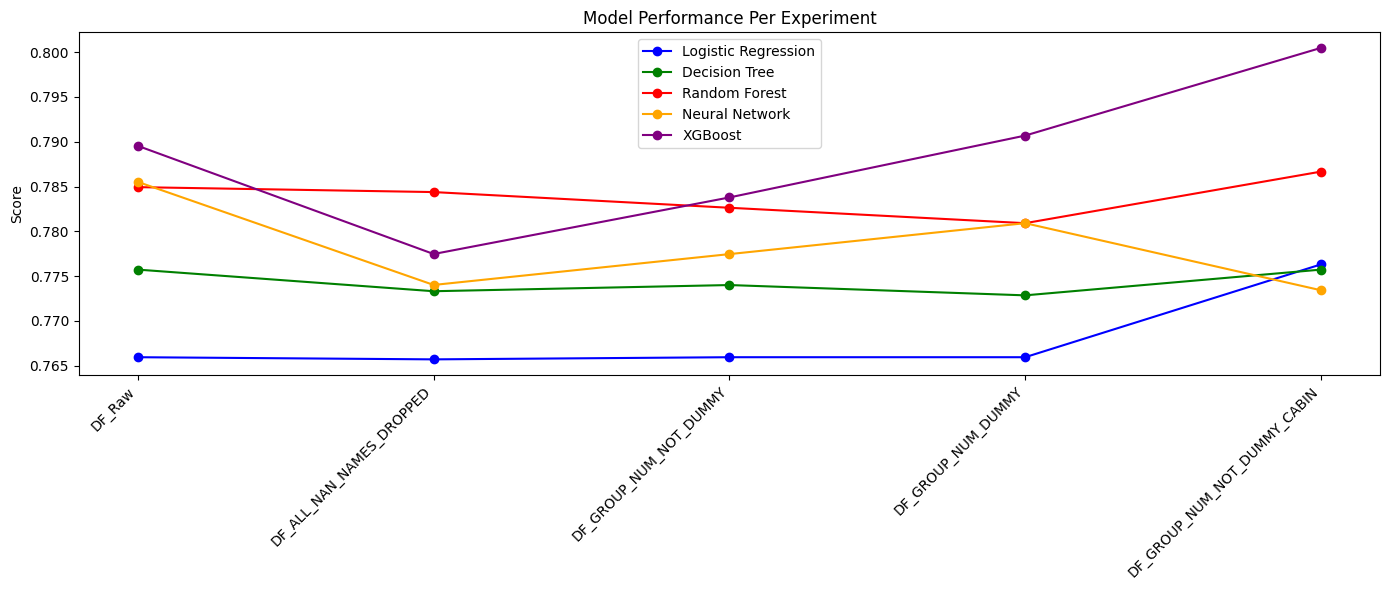

In [110]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_results(fig_size=(14, 6),results=results):
    # convert to dataframe:
    results_df = pd.DataFrame(results)

    # assuming your results are already in a dataframe called results_df
    # with columns: Data, Model, Scorez

    plt.figure(figsize=(fig_size))

    models = results_df['Model'].unique()   # get all model names
    colors = ['blue', 'green', 'red', 'orange', 'purple']

    for model, color in zip(models, colors):
        # filter rows for this model only
        mask = results_df['Model'] == model
        subset = results_df[mask]

        plt.plot(subset['Data'], subset['Score'],
                 marker='o',
                 label=model,
                 color=color)

    plt.xticks(rotation=45, ha='right')
    plt.ylabel('Score')
    plt.title('Model Performance Per Experiment')
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_results()

## Sixth (names-failed)

### Make the names dummies

In [111]:
names = df_raw['Name'].str.split(' ')
names

0         [Maham, Ofracculy]
1            [Juanna, Vines]
2           [Altark, Susent]
3            [Solam, Susent]
4       [Willy, Santantines]
                ...         
8688    [Gravior, Noxnuther]
8689      [Kurta, Mondalley]
8690         [Fayey, Connon]
8691     [Celeon, Hontichre]
8692     [Propsh, Hontichre]
Name: Name, Length: 8693, dtype: object

In [112]:
dummy_df = df.copy()

In [113]:
dummy_df['First_names'] = names.str[0]
dummy_df['Second_names'] = names.str[1]
dummy_df.columns

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'Transported', 'Money_spent', 'HomePlanet_Earth',
       'HomePlanet_Europa', 'HomePlanet_Mars', 'Destination_55 Cancri e',
       'Destination_PSO J318.5-22', 'Destination_TRAPPIST-1e', 'group_num',
       'Cabin_idx0_A', 'Cabin_idx0_B', 'Cabin_idx0_C', 'Cabin_idx0_D',
       'Cabin_idx0_E', 'Cabin_idx0_F', 'Cabin_idx0_G', 'Cabin_idx0_T',
       'Cabin_idx2_P', 'Cabin_idx2_S', 'First_names', 'Second_names'],
      dtype='str')

In [114]:
dummy_df['First_names'].unique(),dummy_df['Second_names'].unique()

(array(['Maham', 'Juanna', 'Altark', ..., 'Ants', 'Gian', 'Chain'],
       shape=(2707,), dtype=object),
 array(['Ofracculy', 'Vines', 'Susent', ..., 'Fort', 'Workmanson',
        'Sionerorly'], shape=(2218,), dtype=object))

In [115]:
dummy_df = pd.get_dummies(dummy_df,columns=['First_names','Second_names'],dtype=int)
dummy_df.columns[:40]

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'Transported', 'Money_spent', 'HomePlanet_Earth',
       'HomePlanet_Europa', 'HomePlanet_Mars', 'Destination_55 Cancri e',
       'Destination_PSO J318.5-22', 'Destination_TRAPPIST-1e', 'group_num',
       'Cabin_idx0_A', 'Cabin_idx0_B', 'Cabin_idx0_C', 'Cabin_idx0_D',
       'Cabin_idx0_E', 'Cabin_idx0_F', 'Cabin_idx0_G', 'Cabin_idx0_T',
       'Cabin_idx2_P', 'Cabin_idx2_S', 'First_names_Aard',
       'First_names_Aarjel', 'First_names_Aark', 'First_names_Aarone',
       'First_names_Aars', 'First_names_Acceleb', 'First_names_Achah',
       'First_names_Achbah', 'First_names_Achib', 'First_names_Achira',
       'First_names_Achiram', 'First_names_Achium', 'First_names_Achyon'],
      dtype='str')

In [116]:
dummy_df['First_names_Aars']

0       0
1       0
2       0
3       0
4       0
       ..
8688    0
8689    0
8690    0
8691    0
8692    0
Name: First_names_Aars, Length: 8693, dtype: int64

### Train

In [117]:
# full_fn("DF_GROUP_NUM_NOT_DUMMY_CABIN_NAMES",dummy_df)

extrmely bad and got the lowest score and takes huge amount of time forget about it

## Seventh

In [118]:
# make the best df file
best_df = df.copy()

In [119]:
# make spending columns ratios
spend_cols

['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

In [120]:
for col in spend_cols:
    df[f"{col}_ratio"] = df[col] / df["Money_spent"].replace(0,1) # to prevent he division on /0
df.columns

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'Transported', 'Money_spent', 'HomePlanet_Earth',
       'HomePlanet_Europa', 'HomePlanet_Mars', 'Destination_55 Cancri e',
       'Destination_PSO J318.5-22', 'Destination_TRAPPIST-1e', 'group_num',
       'Cabin_idx0_A', 'Cabin_idx0_B', 'Cabin_idx0_C', 'Cabin_idx0_D',
       'Cabin_idx0_E', 'Cabin_idx0_F', 'Cabin_idx0_G', 'Cabin_idx0_T',
       'Cabin_idx2_P', 'Cabin_idx2_S', 'RoomService_ratio', 'FoodCourt_ratio',
       'ShoppingMall_ratio', 'Spa_ratio', 'VRDeck_ratio'],
      dtype='str')

### Train

In [121]:
full_fn("DF_GROUP_NUM_NOT_DUMMY_CABIN_MONEY_RATIO",df)

[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN_MONEY_RATIO  | Model : Logistic Regression   | Score : 0.77228 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN_MONEY_RATIO  | Model : Decision Tree   | Score : 0.78148 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN_MONEY_RATIO  | Model : Random Forest   | Score : 0.78493 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN_MONEY_RATIO  | Model : Neural Network   | Score : 0.76998 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN_MONEY_RATIO  | Model : XGBoost   | Score : 0.79586 


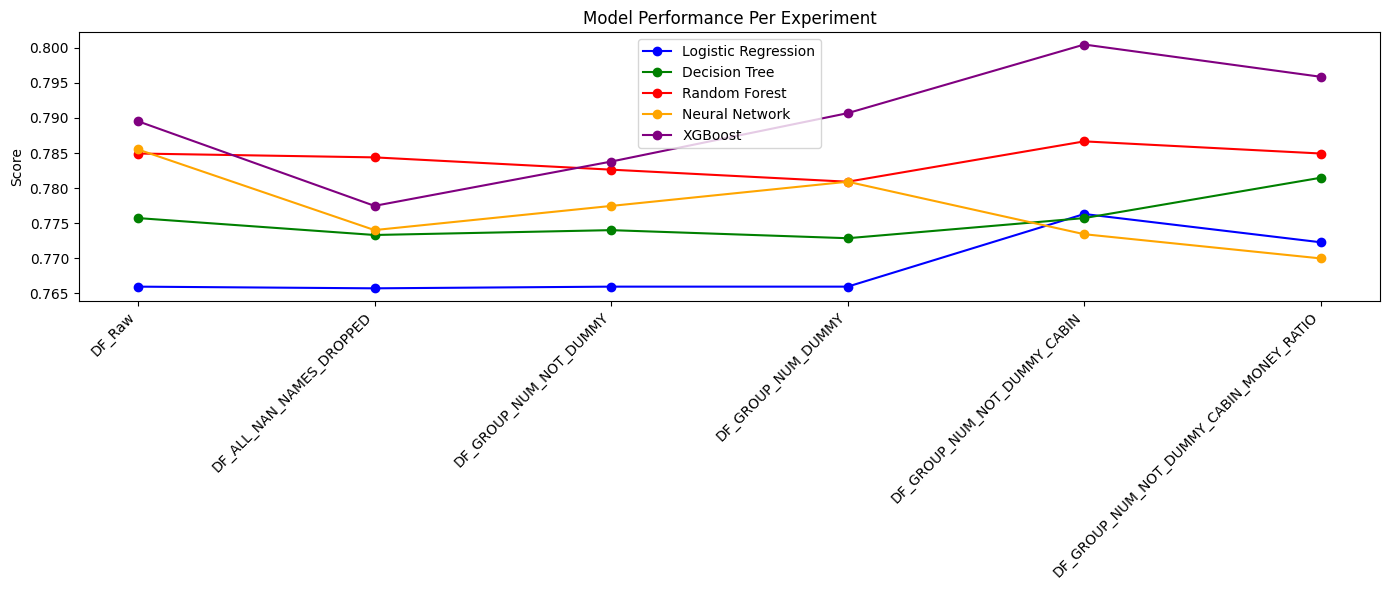

In [122]:
# make the plot
plot_results()

i think it is better to skip it

## Eighth

### Clean

In [123]:
df = best_df.copy()

groupby() uses:  # which returns an object ( so it is just place in the memory that is waiting for one of those instructions)

    df.groupby('HomePlanet')['Age'].mean()
    → average age per planet
      Earth     29.3
      Europa    28.1
      Mars      27.8
    ---------------------------
    df.groupby('HomePlanet')['Transported'].mean()
    → survival rate per planet (very useful for EDA!)
      Earth     0.42  ← 42% transported
      Europa    0.61  ← 61% transported
      Mars      0.52  ← 52% transported
    ---------------------------
    df.groupby('VIP')['Money_spent'].sum()
    → total spending per VIP status
    ---------------------------
    df.groupby('CryoSleep')['Transported'].mean()
    → transport rate for sleeping vs awake
    ---------------------------
    df['GroupSize'] = df.groupby('Group')['Group'].transform('count') # ['Group'] is just for counting how many rows in the df to make the expansion of transform()
                                                                      # so ,we can use any other column for this counting

    → find how many people travel in same group
    → paste that number into every row
    → gives model info about family/group size

    that's it, nothing else in your code uses groupby

In [124]:
# we are going to do the number of the people in the trip from the PassengerId
df['Group'] = df_raw['PassengerId'].str.split('_').str[0]
df['Group_size'] = df.groupby('Group')['Group'].transform('count')
df[['Group','Group_size']].head()

,Group,Group_size
0,0001,1
1,0002,1
2,0003,2
3,0003,2
4,0004,1


In [125]:
# drop the Group
df.drop(['Group'] , axis=1, inplace=True)

In [126]:
df['Group_size'] == 1

0        True
1        True
2       False
3       False
4        True
        ...  
8688     True
8689     True
8690     True
8691    False
8692    False
Name: Group_size, Length: 8693, dtype: bool

In [127]:
# make the IsAlone column
df["IsAlone"] = (df['Group_size'] == 1).astype(int)

In [128]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 29 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CryoSleep                  8693 non-null   float64
 1   Age                        8693 non-null   float64
 2   VIP                        8693 non-null   float64
 3   RoomService                8693 non-null   float64
 4   FoodCourt                  8693 non-null   float64
 5   ShoppingMall               8693 non-null   float64
 6   Spa                        8693 non-null   float64
 7   VRDeck                     8693 non-null   float64
 8   Transported                8693 non-null   int64  
 9   Money_spent                8693 non-null   float64
 10  HomePlanet_Earth           8693 non-null   int64  
 11  HomePlanet_Europa          8693 non-null   int64  
 12  HomePlanet_Mars            8693 non-null   int64  
 13  Destination_55 Cancri e    8693 non-null   int64  
 14  Des

### Train

In [129]:
full_fn("DF_GROUP_NUM_NOT_DUMMY_CABIN_GPSIZE_ISALONE",df=df)

[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN_GPSIZE_ISALONE  | Model : Logistic Regression   | Score : 0.77343 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN_GPSIZE_ISALONE  | Model : Decision Tree   | Score : 0.77573 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN_GPSIZE_ISALONE  | Model : Random Forest   | Score : 0.79241 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN_GPSIZE_ISALONE  | Model : Neural Network   | Score : 0.76538 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN_GPSIZE_ISALONE  | Model : XGBoost   | Score : 0.79988 


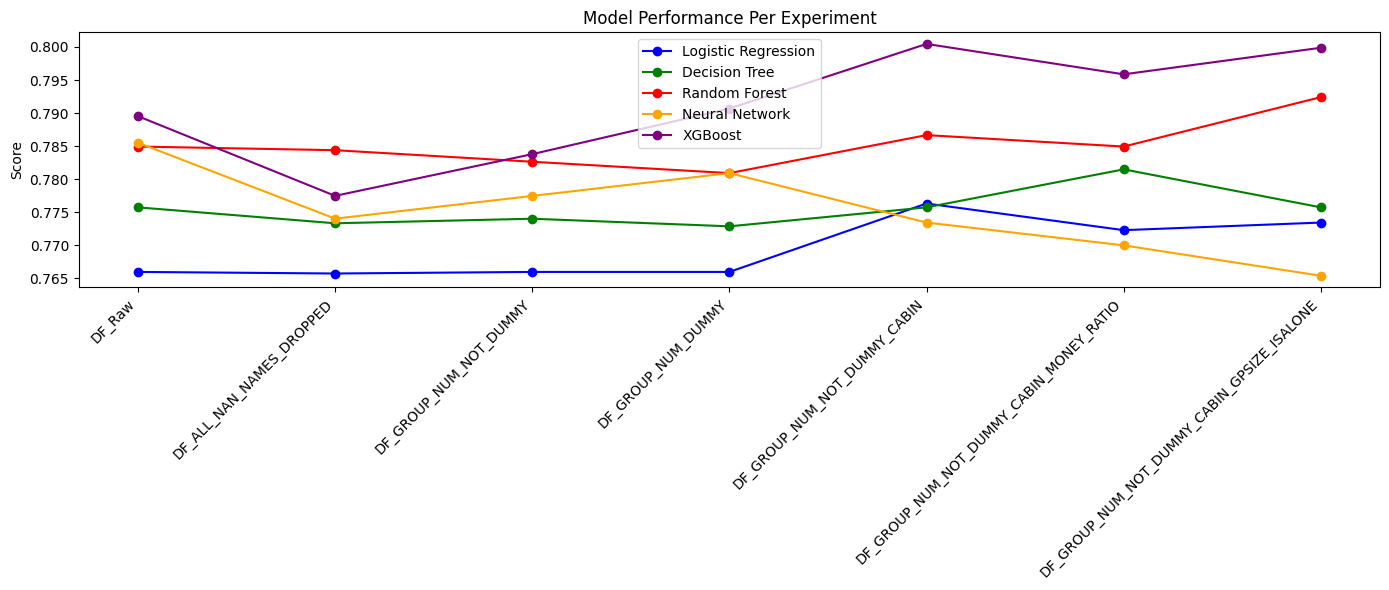

In [130]:
plot_results()

## Ninth

### Drop the Groupsize

In [131]:
df.drop(['Group_size'], axis=1, inplace=True)

### Train

In [132]:
full_fn("DF_GROUP_NUM_NOT_DUMMY_CABIN_ISALONE",df=df)

[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN_ISALONE  | Model : Logistic Regression   | Score : 0.77458 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN_ISALONE  | Model : Decision Tree   | Score : 0.77573 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN_ISALONE  | Model : Random Forest   | Score : 0.79068 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN_ISALONE  | Model : Neural Network   | Score : 0.75446 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_CABIN_ISALONE  | Model : XGBoost   | Score : 0.80334 


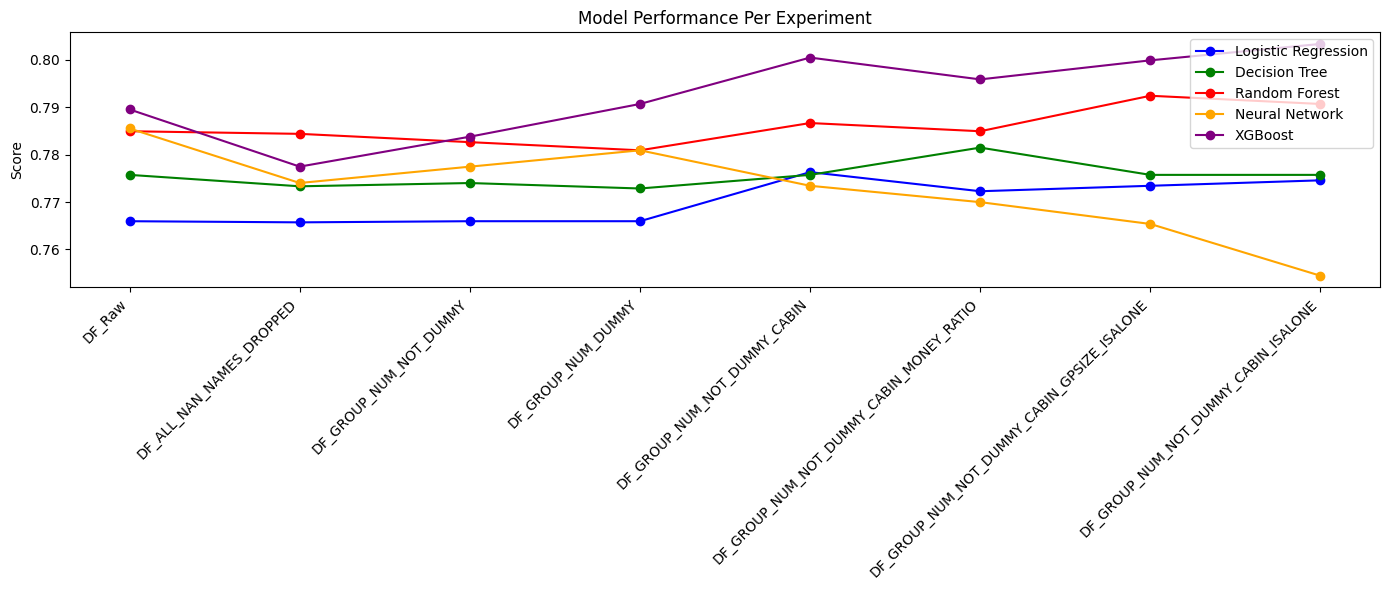

In [133]:
plot_results()

In [134]:
best_df = df.copy()

## Tenth

### Adding the middle cabin number that we have dropped as int and making it between 1,0

In [135]:
cabin_idx1 = df_raw["Cabin"].str.split('/').str[1]
cabin_idx1 = pd.to_numeric(cabin_idx1, errors='coerce')  # convert to number first ( this makes it not crash if there was something that is inconvertable and like if there was a nan it leave it as it is
cabin_idx1 = cabin_idx1.fillna(cabin_idx1.median())      # then fill with median
cabin_idx1 = cabin_idx1 / cabin_idx1.max()               # normalize 0 to 1

In [136]:
df['cabin_idx1'] = cabin_idx1
df['cabin_idx1']

0       0.000000
1       0.000000
2       0.000000
3       0.000000
4       0.000528
          ...   
8688    0.051742
8689    0.791447
8690    0.791975
8691    0.321014
8692    0.321014
Name: cabin_idx1, Length: 8693, dtype: float64

### Train

In [137]:
full_fn("DF_GROUP_NUM_NOT_DUMMY_ALL_CABIN_ISALONE",df)

[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_ALL_CABIN_ISALONE  | Model : Logistic Regression   | Score : 0.77286 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_ALL_CABIN_ISALONE  | Model : Decision Tree   | Score : 0.76481 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_ALL_CABIN_ISALONE  | Model : Random Forest   | Score : 0.79068 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_ALL_CABIN_ISALONE  | Model : Neural Network   | Score : 0.76366 
[INFO]  Data : DF_GROUP_NUM_NOT_DUMMY_ALL_CABIN_ISALONE  | Model : XGBoost   | Score : 0.80736 


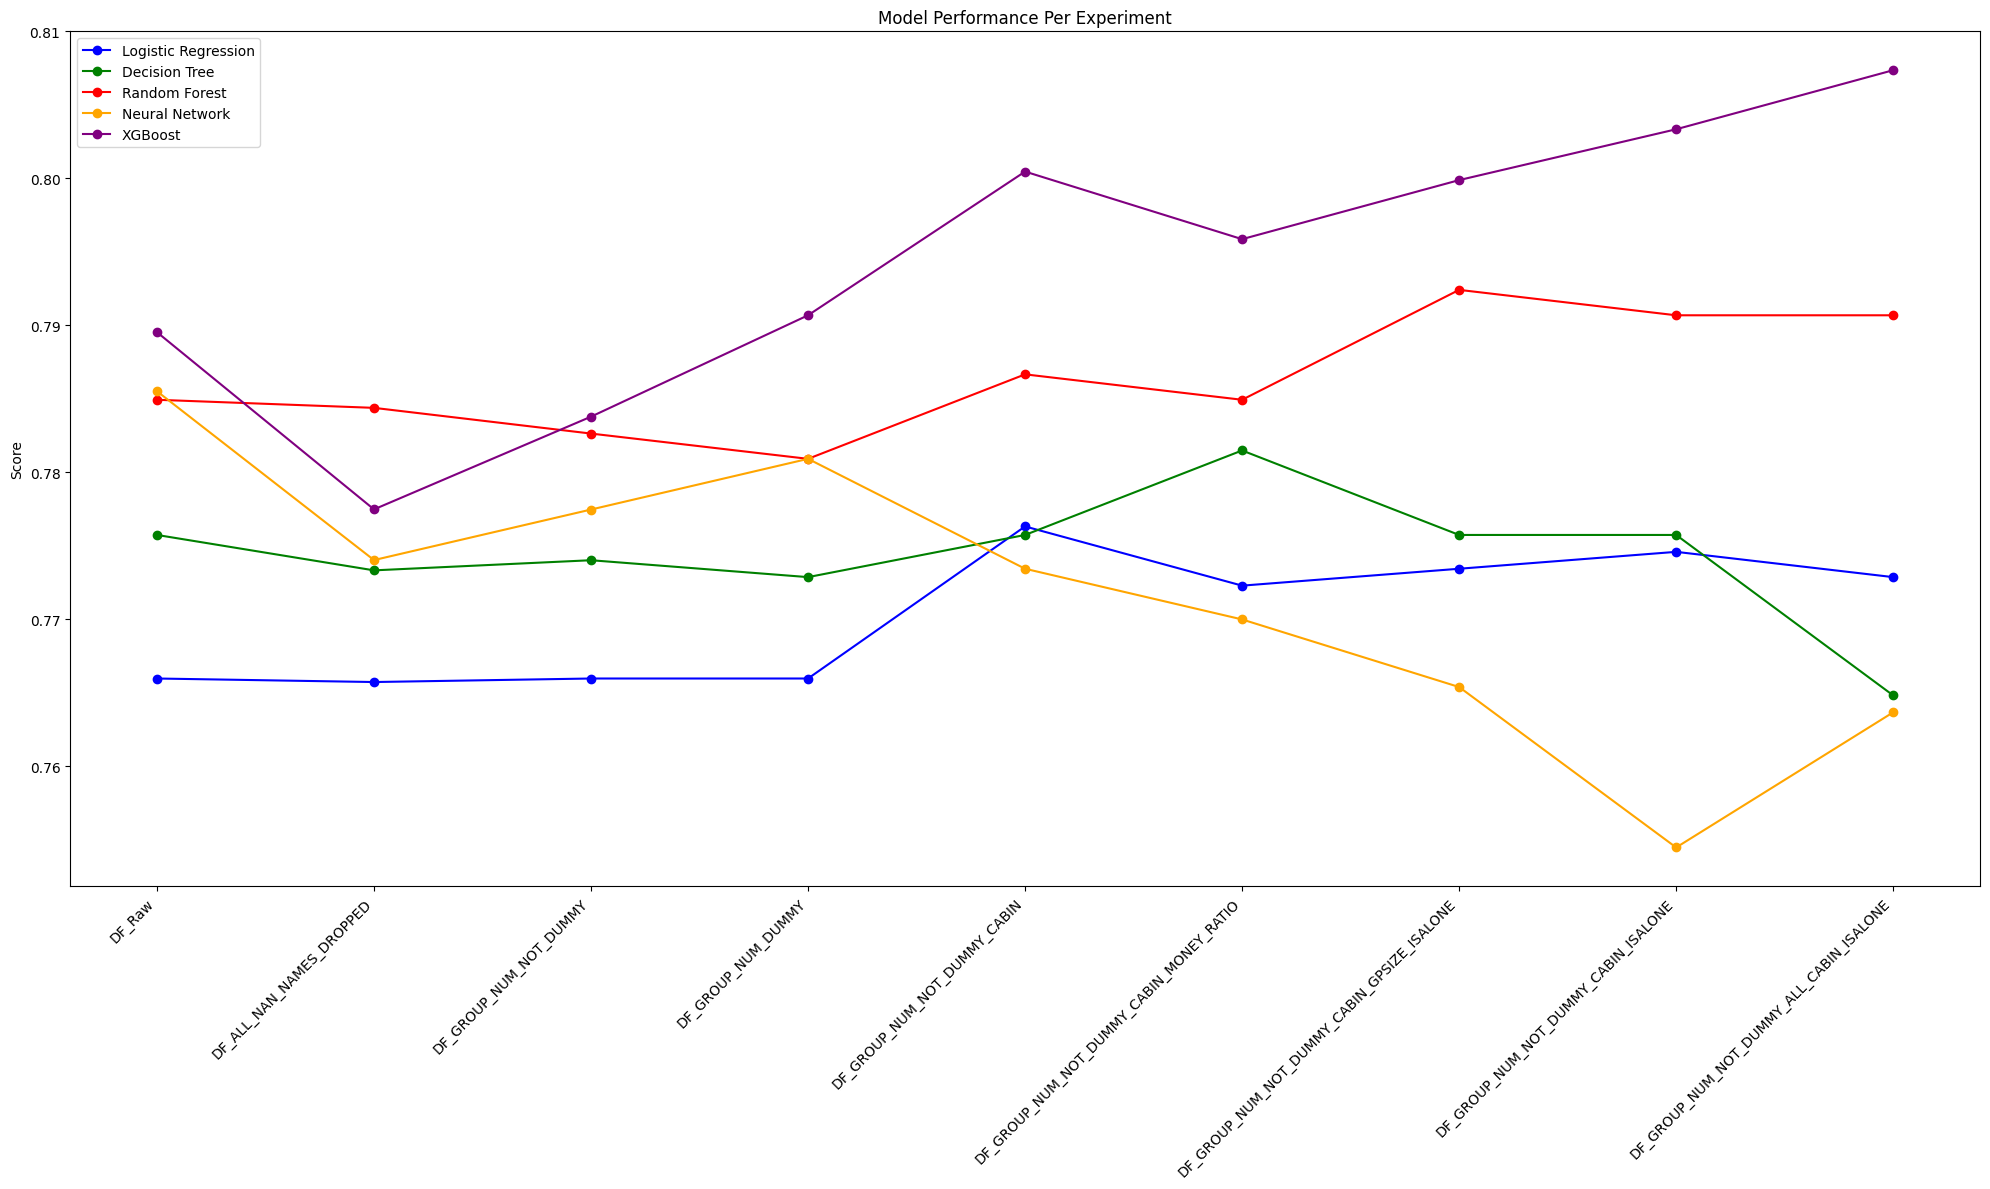

In [138]:
plot_results((20,12))

In [139]:
best_df = df.copy()

## ELEVENTH

# Funcitonizing what we have reached so far

### Make the funcitons

In [140]:
def sleep_cleaner(df,bool=True):
    Money_cols =['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
    # fill spend NaNs for asleep people with 0
    if bool:
        CryoSleep_mask = df['CryoSleep'] == True
        for col in Money_cols:
            df.loc[CryoSleep_mask, col] = df.loc[CryoSleep_mask, col].fillna(0)
    else:
        CryoSleep_mask = df['CryoSleep'] == 1
        for col in Money_cols:
            df.loc[CryoSleep_mask, col] = df.loc[CryoSleep_mask, col].fillna(0)

    return df

In [141]:
def data_cols_splitter(df):
    # making the --> group_num
    df['group_num'] = df['PassengerId'].str.split('_').str[1].astype(int)
    df['Group'] = df['PassengerId'].str.split('_').str[0]

    # making the cabin columns
    df['Cabin_idx0'] = df['Cabin'].str.split('/').str[0]
    df['Cabin_idx1'] = pd.to_numeric(df['Cabin'].str.split('/').str[1],errors='coerce') # make it to numeric before the nans
    df['Cabin_idx2'] = df['Cabin'].str.split('/').str[2]

    # dropping what is not needed
    df.drop(['PassengerId','Cabin','Name'], axis=1, inplace=True)

    return df

In [231]:
def median_mode_cleaner(df,
                        num_cols = ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Cabin_idx1'],
                        cat_cols = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Cabin_idx0', 'Cabin_idx2']):
    # 1. Fill Numerical with Median
    for col in num_cols:
        df[col] = df[col].fillna(df[col].median())

    # 2. Fill Categorical with Mode
    for col in cat_cols:
    # [0] is needed because .mode() returns a Series
        df[col] = df[col].fillna(df[col].mode()[0])

    return df


In [193]:
def prepare_df(df):

    # making the IsAlone column
    df['IsAlone'] = (df.groupby('Group')['Group'].transform('count') == 1).astype(int)

    # dropping what is not needed
    df.drop(['Group'], axis=1, inplace=True)

    # making the dummies
    df = pd.get_dummies(df, columns=['Cabin_idx0', 'Cabin_idx2','HomePlanet','Destination'], dtype=int)

    # normalize age
    df['Age'] = df['Age'] / df['Age'].max()

    # making the money and total money
    Money_cols =['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
    df['Total_Money'] = df[Money_cols].sum(axis=1)

    # log + normalize money columns
    All_money_cols = Money_cols + ['Total_Money']
    for col in All_money_cols:
        df[col] = np.log(df[col] + 1)
        df[col] = df[col] / df[col].max()

    # normalizing the cabin_idx1
    df['Cabin_idx1'] = df['Cabin_idx1'] / df['Cabin_idx1'].max()  # normalize 0 to 1

    # turning any bool to 0,1
    bool_cols = df.select_dtypes(include='bool').columns
    df[bool_cols] = df[bool_cols].astype(int)

    # Convert the boolean-objects to integers (0 and 1)
    df['CryoSleep'] = df['CryoSleep'].astype(int)
    df['VIP'] = df['VIP'].astype(int)

    return df


### Try it

#### Make the data

In [194]:
dummy_df = pd.read_csv(trn_data)

In [195]:
dummy_df.isna().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

In [196]:
dummy_df.head(2)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True


In [197]:
dummy_df = sleep_cleaner(dummy_df,True)

In [198]:
dummy_df.isna().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     113
FoodCourt       113
ShoppingMall    112
Spa             118
VRDeck          126
Name            200
Transported       0
dtype: int64

In [199]:
dummy_df.head(2)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True


In [200]:
dummy_df = data_cols_splitter(dummy_df)

In [201]:
dummy_df.head(2)

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,group_num,Group,Cabin_idx0,Cabin_idx1,Cabin_idx2
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,False,1,0001,B,0.0,P
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,True,1,0002,F,0.0,S


In [202]:
dummy_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   HomePlanet    8492 non-null   str    
 1   CryoSleep     8476 non-null   object 
 2   Destination   8511 non-null   str    
 3   Age           8514 non-null   float64
 4   VIP           8490 non-null   object 
 5   RoomService   8580 non-null   float64
 6   FoodCourt     8580 non-null   float64
 7   ShoppingMall  8581 non-null   float64
 8   Spa           8575 non-null   float64
 9   VRDeck        8567 non-null   float64
 10  Transported   8693 non-null   bool   
 11  group_num     8693 non-null   int64  
 12  Group         8693 non-null   object 
 13  Cabin_idx0    8494 non-null   object 
 14  Cabin_idx1    8494 non-null   float64
 15  Cabin_idx2    8494 non-null   object 
dtypes: bool(1), float64(7), int64(1), object(5), str(2)
memory usage: 1.1+ MB


In [203]:
num_cols = ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Cabin_idx1']
cat_cols = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Cabin_idx0', 'Cabin_idx2']

In [204]:
# 3. Fill Numerical with Median
for col in num_cols:
    dummy_df[col] = dummy_df[col].fillna(dummy_df[col].median())

# 4. Fill Categorical with Mode
for col in cat_cols:
    # [0] is needed because .mode() returns a Series
    dummy_df[col] = dummy_df[col].fillna(dummy_df[col].mode()[0])

In [205]:
dummy_df.isna().sum()

HomePlanet      0
CryoSleep       0
Destination     0
Age             0
VIP             0
RoomService     0
FoodCourt       0
ShoppingMall    0
Spa             0
VRDeck          0
Transported     0
group_num       0
Group           0
Cabin_idx0      0
Cabin_idx1      0
Cabin_idx2      0
dtype: int64

In [206]:
# 5. Now it is safe to run prepare_df
dummy_df = prepare_df(dummy_df)

In [207]:
dummy_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 29 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CryoSleep                  8693 non-null   int64  
 1   Age                        8693 non-null   float64
 2   VIP                        8693 non-null   int64  
 3   RoomService                8693 non-null   float64
 4   FoodCourt                  8693 non-null   float64
 5   ShoppingMall               8693 non-null   float64
 6   Spa                        8693 non-null   float64
 7   VRDeck                     8693 non-null   float64
 8   Transported                8693 non-null   int64  
 9   group_num                  8693 non-null   int64  
 10  Cabin_idx1                 8693 non-null   float64
 11  IsAlone                    8693 non-null   int64  
 12  Cabin_idx0_A               8693 non-null   int64  
 13  Cabin_idx0_B               8693 non-null   int64  
 14  Cab

In [208]:
dummy_df.head()

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,group_num,...,Cabin_idx0_T,Cabin_idx2_P,Cabin_idx2_S,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e,Total_Money
0,0,0.493671,0,0.000000,0.000000,0.000000,0.000000,0.000000,0,1,...,0,1,0,0,1,0,0,0,1,0.000000
1,0,0.303797,0,0.491170,0.223493,0.323723,0.629907,0.377219,1,1,...,0,0,1,1,0,0,0,0,1,0.629361
2,0,0.734177,1,0.395423,0.794185,0.000000,0.879710,0.387660,0,1,...,0,0,1,0,1,0,0,0,1,0.881525
3,0,0.417722,0,0.000000,0.694741,0.588099,0.809679,0.522016,0,2,...,0,0,1,0,1,0,0,0,1,0.815178
4,0,0.202532,0,0.597392,0.413743,0.499171,0.632770,0.108866,1,1,...,0,0,1,1,0,0,0,0,1,0.666839


#### Train

In [217]:
full_fn("DF_FUNCTIONIZED",df=dummy_df)

[INFO]  Data : DF_FUNCTIONIZED  | Model : Logistic Regression   | Score : 0.77286 
[INFO]  Data : DF_FUNCTIONIZED  | Model : Decision Tree   | Score : 0.76538 
[INFO]  Data : DF_FUNCTIONIZED  | Model : Random Forest   | Score : 0.78953 
[INFO]  Data : DF_FUNCTIONIZED  | Model : Neural Network   | Score : 0.75848 
[INFO]  Data : DF_FUNCTIONIZED  | Model : XGBoost   | Score : 0.80506 


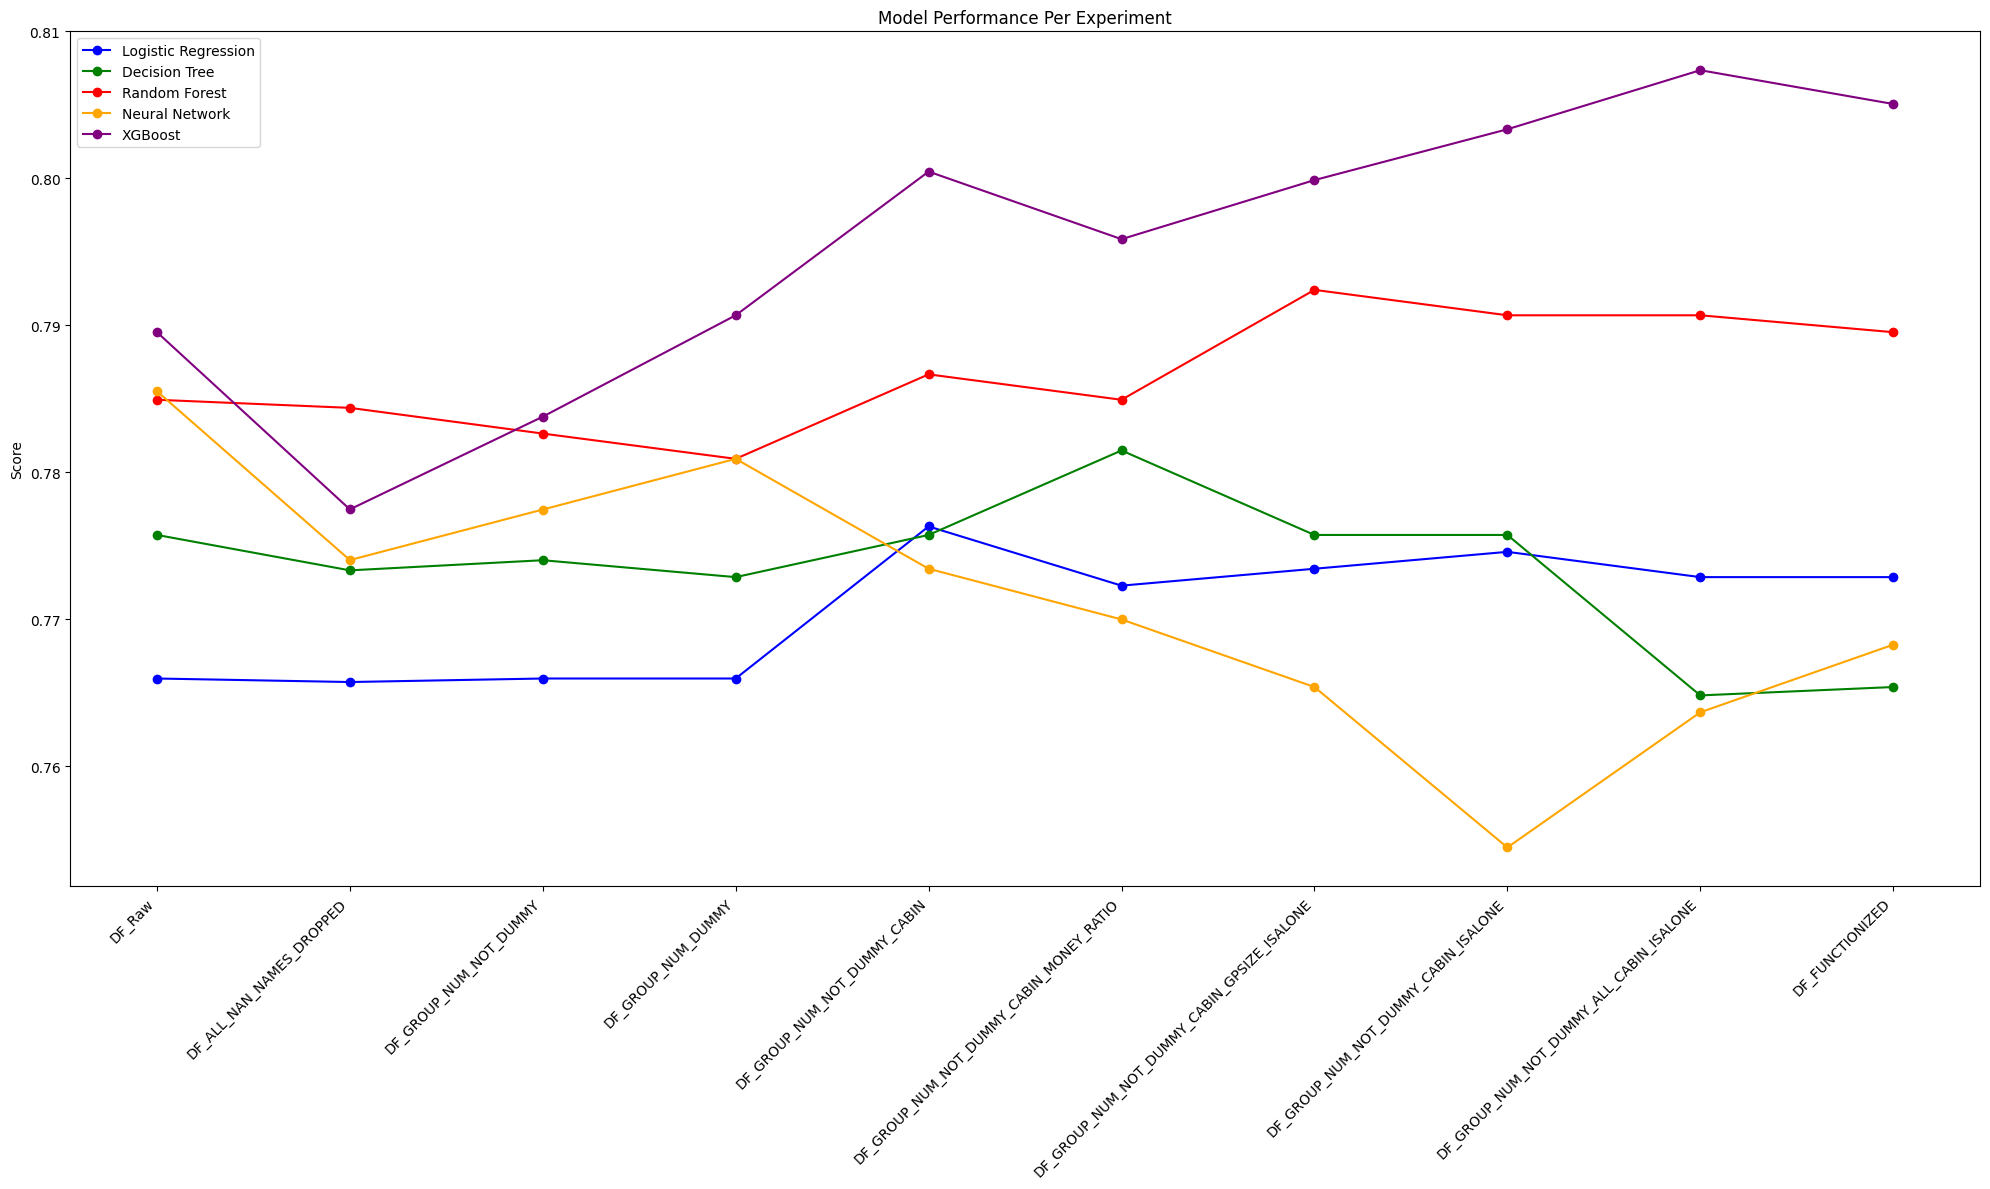

In [211]:
plot_results((20,12))

This small drop is because of some thing that I have made during manual experimentation. Which was that. I first got the mode() for cabin and then split it them into three, then dropped the middle index, then got back the middle index and got the median() for it. So that was the difference. But ma what is now in the function is more stable and better.

# Make a kaggle submission

## Make the best model (XGBoost)

In [218]:
# Use the exact same hyperparameters
model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    eval_metric='logloss',
    random_state=42
)

## Make the train data

In [219]:
df = pd.read_csv(trn_data)

In [221]:
x_trn = df.drop('Transported', axis=1)
y_trn = df['Transported'].astype(int)

In [222]:
x_trn.head(2)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines


In [223]:
y_trn.head(2)

0    0
1    1
Name: Transported, dtype: int64

In [224]:
x_trn = sleep_cleaner(x_trn,True)

In [225]:
x_trn = data_cols_splitter(x_trn)

In [226]:
# 3. Fill Numerical with Median
for col in num_cols:
    x_trn[col] = x_trn[col].fillna(x_trn[col].median())

# 4. Fill Categorical with Mode
for col in cat_cols:
    # [0] is needed because .mode() returns a Series
    x_trn[col] = x_trn[col].fillna(x_trn[col].mode()[0])

In [227]:
x_trn = prepare_df(x_trn)

## Train the model

In [228]:
model.fit(x_trn, y_trn)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

## Make the test_df ready

In [241]:
test_df = pd.read_csv(tst_data)
test_ids = test_df['PassengerId']

In [242]:
test_df = sleep_cleaner(test_df, True)
test_df = data_cols_splitter(test_df)
test_df = median_mode_cleaner(test_df)
test_df = prepare_df(test_df)

test_df.head()

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,group_num,Cabin_idx1,...,Cabin_idx0_T,Cabin_idx2_P,Cabin_idx2_S,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e,Total_Money
0,1,0.341772,0,0.000000,0.000000,0.000000,0.000000,0.000000,1,0.001587,...,0,0,1,1,0,0,0,0,1,0.000000
1,0,0.240506,0,0.000000,0.227135,0.000000,0.802965,0.000000,1,0.002116,...,0,0,1,1,0,0,0,0,1,0.762556
2,1,0.392405,0,0.000000,0.000000,0.000000,0.000000,0.000000,1,0.000000,...,0,0,1,0,1,0,1,0,0,0.000000
3,0,0.481013,0,0.000000,0.868340,0.000000,0.525885,0.636623,1,0.000529,...,0,0,1,0,1,0,0,0,1,0.854908
4,0,0.253165,0,0.256295,0.000000,0.715403,0.000000,0.000000,1,0.002646,...,0,0,1,1,0,0,0,0,1,0.620743


## Make the preds and the Submission file

In [243]:
# make the preds
preds = model.predict(test_df)
preds

array([1, 0, 1, ..., 1, 1, 1], shape=(4277,))

In [244]:
# make the submission
submission = pd.DataFrame({
    'PassengerId': test_ids,
    'Transported': preds.astype(bool)   # Kaggle expects True/False
})
submission.head()

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True


In [245]:
submission.to_csv("space_titanic_submission_1.csv", index=False)

# Continue Experiments

## Making a funciton that makes us all of what is there (data and kaggle submission, so that we can just change the just the data funcitons or the model params and just ge the submission file)

In [247]:
num_cols

['Age',
 'RoomService',
 'FoodCourt',
 'ShoppingMall',
 'Spa',
 'VRDeck',
 'Cabin_idx1']

In [251]:
def make_submission(train_df,
                    submission_file_name,
                    n_estimators=300,
                    max_depth=5,
                    learning_rate=0.05,
                    eval_metric='logloss',
                    random_state=42,
                    ):
    # make the model
    model = XGBClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        eval_metric=eval_metric,
        random_state=random_state
    )

    ## Make the train Data
    x_trn = train_df.drop('Transported', axis=1)
    y_trn = train_df['Transported'].astype(int)
    x_trn = sleep_cleaner(x_trn, True)
    x_trn = data_cols_splitter(x_trn)
    x_trn = median_mode_cleaner(x_trn)
    x_trn = prepare_df(x_trn)

    ## Train the model
    model.fit(x_trn, y_trn)

    ## Make the test_df ready
    test_df = pd.read_csv(tst_data)
    test_ids = test_df['PassengerId']
    test_df = sleep_cleaner(test_df, True)
    test_df = data_cols_splitter(test_df)
    test_df = median_mode_cleaner(test_df)
    test_df = prepare_df(test_df)

    # make the preds
    preds = model.predict(test_df)

    # make the submission
    submission = pd.DataFrame({
        'PassengerId': test_ids,
        'Transported': preds.astype(bool)  # Kaggle expects True/False
    })
    # make it to csv
    submission.to_csv(f"{submission_file_name}.csv", index=False)

## Experiment 1 --> make a deck_side

In [258]:
def prepare_df(df):

    # making the IsAlone column
    df['IsAlone'] = (df.groupby('Group')['Group'].transform('count') == 1).astype(int)

    # dropping what is not needed
    df.drop(['Group'], axis=1, inplace=True)

    # === NEW: Create powerful Deck_Side feature BEFORE dummies ===
    df['Deck_Side'] = df['Cabin_idx0'] + '_' + df['Cabin_idx2']

    # making the dummies (now includes Deck_Side)
    df = pd.get_dummies(df, columns=['Cabin_idx0', 'Cabin_idx2', 'Deck_Side',
                                     'HomePlanet', 'Destination'], dtype=int)

    # normalize age
    df['Age'] = df['Age'] / df['Age'].max()

    # making the money and total money
    Money_cols =['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
    df['Total_Money'] = df[Money_cols].sum(axis=1)

    # log + normalize money columns
    All_money_cols = Money_cols + ['Total_Money']
    for col in All_money_cols:
        df[col] = np.log(df[col] + 1)
        df[col] = df[col] / df[col].max()

    # normalizing the cabin_idx1
    df['Cabin_idx1'] = df['Cabin_idx1'] / df['Cabin_idx1'].max()  # normalize 0 to 1

    # turning any bool to 0,1
    bool_cols = df.select_dtypes(include='bool').columns
    df[bool_cols] = df[bool_cols].astype(int)

    # Convert the boolean-objects to integers (0 and 1)
    df['CryoSleep'] = df['CryoSleep'].astype(int)
    df['VIP'] = df['VIP'].astype(int)

    return df

In [259]:
trn_df = pd.read_csv(trn_data)

In [255]:
make_submission(trn_df, 'space_titanic_submission_2')

## Experiment 2 --> ( making the KNN to fill missing values )

In [262]:
from sklearn.impute import KNNImputer

def impute_with_knn(train_df,
                    test_df,
                    num_cols, # num_cols is list of column names that contain numbers and may have NaNs
                    n_neighbors=5): # n_neighbors is how many similar rows to look into each time
    # 1. Create the imputer tool
    imputer = KNNImputer(n_neighbors=n_neighbors)

    # 2. Make a copy of only the numerical columns from train
    train_num = train_df[num_cols].copy()

    # 3. Train (fit) the imputer using ONLY the training Data
    imputer.fit(train_num)                    # ← VERY IMPORTANT

    # 4. Fill missing values in train Data
    train_df[num_cols] = imputer.transform(train_num)

    # 5. Fill missing values in test Data (using what it learned from train)
    test_df[num_cols]  = imputer.transform(test_df[num_cols])

    # 6. Return the updated dataframes
    return train_df, test_df

In [263]:
def KNN_cleaner(trn_df,
                tst_df,
                n_neighbors=5,
                num_cols = ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Cabin_idx1'],
                cat_cols = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Cabin_idx0', 'Cabin_idx2']):

    # 1. use the KNN
    trn_df, tst_df= impute_with_knn(trn_df,
                                       tst_df,
                                       num_cols,
                                       n_neighbors=n_neighbors)

    # 2. Fill Categorical with Mode
    for col in cat_cols:
        mode = trn_df[col].mode()[0]
        trn_df[col] = trn_df[col].fillna(mode)
        tst_df[col] = tst_df[col].fillna(mode)

    return trn_df , tst_df

In [264]:
def make_submission(trn_df,
                    submission_file_name,
                    n_estimators=300,
                    max_depth=5,
                    learning_rate=0.05,
                    eval_metric='logloss',
                    random_state=42,
                    ):

    ## intialize the Data
    # train
    x_trn = trn_df.drop('Transported', axis=1)
    y_trn = trn_df['Transported'].astype(int)
    # test
    tst_df = pd.read_csv(tst_data)
    tst_ids = tst_df['PassengerId']

    ## make the 2 funcitons
    # train
    x_trn = sleep_cleaner(x_trn, True)
    x_trn = data_cols_splitter(x_trn)
    # test
    tst_df = sleep_cleaner(tst_df, True)
    tst_df = data_cols_splitter(tst_df)

    ## KNN
    x_trn,tst_df = KNN_cleaner(x_trn,tst_df)

    ## prepare Data
    x_trn = prepare_df(x_trn)
    tst_df = prepare_df(tst_df)

    ## Train the model
    model.fit(x_trn, y_trn)

    # make the preds
    preds = model.predict(tst_df)

    # make the submission
    submission = pd.DataFrame({
        'PassengerId': tst_ids,
        'Transported': preds.astype(bool)  # Kaggle expects True/False
    })
    # make it to csv
    submission.to_csv(f"{submission_file_name}.csv", index=False)

In [265]:
make_submission(trn_df,"space_titanic_submission_4")

### This is the best submission here --> lets make the function more easy so that what we need to change is just the trn_data or the models

In [272]:
def data_handeling(trn_df,
                              submission_file_name,):
    ## intialize the Data
    # train
    x_trn = trn_df.drop('Transported', axis=1)
    y_trn = trn_df['Transported'].astype(int)
    # test
    tst_df = pd.read_csv(tst_data)
    tst_ids = tst_df['PassengerId']

    ## make the 2 funcitons
    # train
    x_trn = sleep_cleaner(x_trn, True)
    x_trn = data_cols_splitter(x_trn)
    # test
    tst_df = sleep_cleaner(tst_df, True)
    tst_df = data_cols_splitter(tst_df)

    ## KNN
    x_trn,tst_df = KNN_cleaner(x_trn,tst_df)

    ## prepare Data
    x_trn = prepare_df(x_trn)
    tst_df = prepare_df(tst_df)

    return x_trn , y_trn , tst_df , tst_ids

In [273]:
def submission_handeling(preds,tst_ids,submission_file_name):
    # make the submission
    submission = pd.DataFrame({
        'PassengerId': tst_ids,
        'Transported': preds.astype(bool)  # Kaggle expects True/False
    })
    # make it to csv
    submission.to_csv(f"{submission_file_name}.csv", index=False)

In [274]:
def make_preds(x_trn,
               y_trn,
               tst_df,
               n_estimators=300,
               max_depth=5,
               learning_rate=0.05,
               eval_metric='logloss',
               random_state=42):
    model = XGBClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        eval_metric=eval_metric,
        random_state=random_state
    )
    ## Train the model
    model.fit(x_trn, y_trn)

    # make the preds
    preds = model.predict(tst_df)
    return preds

In [275]:
def make_submission(trn_df,
                    submission_file_name,
                    n_estimators=300,
                    max_depth=5,
                    learning_rate=0.05,
                    eval_metric='logloss',
                    random_state=42,
                    ):

    x_trn , y_trn , tst_df , tst_ids =  data_handeling(trn_df,submission_file_name)
    preds = make_preds(x_trn,
                       y_trn,
                       tst_df,
                       n_estimators=n_estimators,
                       max_depth=max_depth,
                       learning_rate=learning_rate,
                       eval_metric=eval_metric,
                       random_state=random_state)
    submission_handeling(preds,tst_ids,submission_file_name)

## Experiment 3


### here we  are going to add more features

In [285]:
def prepare_df(df):

    # making the IsAlone column
    df['IsAlone'] = (df.groupby('Group')['Group'].transform('count') == 1).astype(int)

    # dropping what is not needed
    df.drop(['Group'], axis=1, inplace=True)

    # making the dummies
    df = pd.get_dummies(df, columns=['Cabin_idx0', 'Cabin_idx2','HomePlanet','Destination'], dtype=int)

    # make an age Feature
    # Create bins for age groups. pd.cut automatically assigns numerical codes to categories.
    # 0 = child, 1 = adult, 2 = elderly
    df['AgeGroup'] = pd.cut(
        df['Age'],
        bins=[-1, 17, 60, 200], # The borders of our groups: <18, 18-60, >60
        labels=[0, 1, 2]        # The integer values assigned to each group
    ).astype(int)


    # normalize age
    df['Age'] = df['Age'] / df['Age'].max()

    # making the money and total money
    Money_cols =['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
    df['Total_Money'] = df[Money_cols].sum(axis=1)

    # add feature ---> spend money?
    df['Has_spent'] = (df['Total_Money'] > 0).astype(int)

    # log + normalize money columns
    All_money_cols = Money_cols + ['Total_Money']
    for col in All_money_cols:
        df[col] = np.log(df[col] + 1)
        df[col] = df[col] / df[col].max()

    # normalizing the cabin_idx1
    df['Cabin_idx1'] = df['Cabin_idx1'] / df['Cabin_idx1'].max()  # normalize 0 to 1

    # turning any bool to 0,1
    bool_cols = df.select_dtypes(include='bool').columns
    df[bool_cols] = df[bool_cols].astype(int)

    # Convert the boolean-objects to integers (0 and 1)
    df['CryoSleep'] = df['CryoSleep'].astype(int)
    df['VIP'] = df['VIP'].astype(int)

    return df


In [286]:
make_submission(trn_df,'space_titanic_submission_5')

In [31]:
class player():
    def __init__(self,health=100,shield=100):
        self.health = health
        self.shield = shield
    def damage(self,damage):
        if self.shield<damage :
            damage -= self.shield
            self.shield = 0
            if self.health<damage:
                print("He is dead")
            else:
                self.health -= damage
                print(f'current health = {self.health}')
        else:
            self.shield -= damage
            print(f"current shield = {self.shield}")

player_1 = player()

In [39]:
player_1.damage(30)

He is dead
